<a href="https://colab.research.google.com/github/MohammedHany123/akt26_gpu_dev/blob/main/L1_Air_Quality_Data_Preprocessing_Notebook_Ne3Na3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
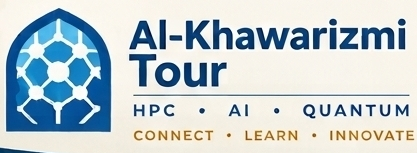
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 1 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Data Quality &amp; Preprocessing — Beijing Air Quality · Hands-on &amp; Week-1 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos used during the lecture (slide references in each heading) · Part B: the week-long <b>Air-Quality Data Challenge</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A11) | during the 2-hour lecture | each demo matches a slide of the deck / a card of the speaker script |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells, write your report, prepare your pitch |

**Dataset:** *Beijing Multi-Site Air Quality* — UCI Machine Learning Repository, dataset 501. Hourly PM2.5, PM10, SO2, NO2, CO, O3 (µg/m³) and TEMP, PRES, DEWP, RAIN, wind direction `wd`, wind speed `WSPM` at **12 stations**, **1 Mar 2013 – 28 Feb 2017**, **420,768 rows**, with real missing values (NA).
Reference: Zhang, S. et al. (2017) *Cautionary tales on air-quality improvement in Beijing*, Proc. R. Soc. A.

**Data access:** the notebook downloads the archive from UCI (≈ 8 MB) and caches it. If you already have the `PRSA_Data_*.csv` files, put them next to the notebook. Offline, a synthetic stand-in with the same columns is generated so the code still runs.

**Requirements:** Python ≥ 3.9, `numpy`, `pandas`, `matplotlib`, `scikit-learn ≥ 1.2`. Works in Jupyter, VS Code or Google Colab. Tip: on a laptop, run Part A first on `SAMPLE_STATIONS` (4 stations) and switch to all 12 for the challenge.

## 0 · Setup — set your team number first

In [ ]:
TEAM_ID = 1135           # <-- your team number: it seeds YOUR version of the merged dataset
SEED = 1000 + TEAM_ID

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)
import sklearn; print("scikit-learn", sklearn.__version__, "| team", TEAM_ID)

scikit-learn 1.6.1 | team 1135


In [ ]:
import os
import glob

# Look for gzip or csv.gz files in the current directory
gz_files = glob.glob("*.gz") + glob.glob("*.csv.gz") + glob.glob("beijing*")
print("Found cached files:", gz_files)

# Delete them
for f in gz_files:
    if os.path.exists(f):
        os.remove(f)
        print(f"Removed corrupted file: {f}")

Found cached files: []


---
# Part A · Guided demos
## A1 · Load the 12 station files  *(slides 2 & 13)*

In [ ]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw.head()

Loaded 420,768 rows x 18 columns from UCI download


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


## A2 · The scenario: a careless merge + an untouched final year  *(slides 27 & 32)*
* **Test year** = 1 Mar 2016 – 28 Feb 2017 (the real data, untouched) — used **only in Task 6**.
* **Training years** = 1 Mar 2013 – 29 Feb 2016 → turned into your team's *merged export* with realistic merge errors.

In [ ]:
SPLIT = pd.Timestamp("2016-03-01")
train_raw = raw[raw["datetime"] < SPLIT].reset_index(drop=True)
test_year = raw[raw["datetime"] >= SPLIT].reset_index(drop=True)
print(f"training years: {len(train_raw):,} rows | test year: {len(test_year):,} rows")

training years: 315,648 rows | test year: 105,120 rows


## A3 · Generate your team's merged export
The function reproduces problems of a careless multi-station merge. **Treat it as a black box during the challenge** — your job is to *discover* the problems from the data.

In [ ]:
def make_dirty(df, seed):
    r = np.random.default_rng(seed)
    d = df.drop(columns=["datetime"]).copy()
    n = len(d)
    st_unit, st_tz, st_stuck = r.choice(STATIONS, 3, replace=False)
    # 1) consistency: station-name variants and lower-case wind directions
    v = r.random(n)
    d.loc[v < .05, "station"] = d.loc[v < .05, "station"].str.upper()
    d.loc[(v >= .05) & (v < .10), "station"] = d.loc[(v >= .05) & (v < .10), "station"].str.lower() + " "
    w = r.random(n) < .02
    d.loc[w, "wd"] = d.loc[w, "wd"].str.lower()
    stn = d["station"].str.strip().str.title()
    # 2) accuracy: one station exported CO in mg/m3 during 2014
    m = (stn == st_unit) & (d["year"] == 2014)
    d.loc[m, "CO"] = d.loc[m, "CO"] / 1000
    # 3) timeliness: one station exported in UTC during 2015 (8 h behind Beijing time)
    m = (stn == st_tz) & (d["year"] == 2015)
    dt = pd.to_datetime(d.loc[m, ["year", "month", "day", "hour"]]) - pd.Timedelta(hours=8)
    d.loc[m, "year"], d.loc[m, "month"], d.loc[m, "day"], d.loc[m, "hour"] = dt.dt.year, dt.dt.month, dt.dt.day, dt.dt.hour
    # 4) validity: stuck PM2.5 sensor (flat lines), sentinel codes, PM2.5/PM10 column swap
    idx = np.flatnonzero((stn == st_stuck).values)
    for s0 in r.choice(idx[:-80], 8, replace=False):
        L = int(r.integers(24, 73)); rows = d.index[s0:s0 + L]
        d.loc[rows, "PM2.5"] = d.loc[rows[0], "PM2.5"]
    for c in ["TEMP", "PRES"]:
        d.loc[r.random(n) < .002, c] = -999
    sw = r.random(n) < .003
    d.loc[sw, ["PM2.5", "PM10"]] = d.loc[sw, ["PM10", "PM2.5"]].values
    # 5) completeness: extra random logger drop-outs in NO2
    d.loc[r.random(n) < .03, "NO2"] = np.nan
    # 6) uniqueness: one station-month re-uploaded (slightly different O3) + scattered exact duplicates
    s_dup = r.choice(STATIONS); y_dup, m_dup = 2014, int(r.integers(1, 13))
    re = d[(stn == s_dup) & (d["year"] == y_dup) & (d["month"] == m_dup)].copy()
    re["O3"] = re["O3"] + 1
    d = pd.concat([d, re, d.sample(frac=.005, random_state=seed)], ignore_index=True)
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

dirty = make_dirty(train_raw, SEED)
dirty.to_csv(f"beijing_merged_team{TEAM_ID}.csv.gz", index=False)
print(f"merged export: {dirty.shape[0]:,} rows -> beijing_merged_team{TEAM_ID}.csv.gz")
dirty.head()

merged export: 317,970 rows -> beijing_merged_team1135.csv.gz


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,6378,2013,11,21,17,89.0,117.0,37.0,92.0,NaN,6.8544,7.5,1021.4,-7.4,0.0,WSW,1.3,Dongsi
1,23504,2015,11,5,7,175.0,175.0,7.0,29.0,1100.0,46.0000,11.0,1018.0,6.7,0.0,NNE,0.9,Huairou
2,22345,2015,9,18,0,166.0,166.0,4.0,145.0,1400.0,2.0000,21.4,1007.6,17.4,0.0,NE,0.8,Changping
3,8285,2014,2,9,4,7.0,6.0,5.0,NaN,300.0,NaN,-12.7,1028.0,-20.5,0.0,WNW,1.1,Huairou
4,23252,2015,10,25,19,39.0,82.0,6.0,87.0,1000.0,12.0000,12.4,1020.7,-1.5,0.0,SSE,1.0,Aotizhongxin


## A4 · First look  *(slides 11, 13 & 14)*

In [ ]:
df = dirty.copy()
print("shape:", df.shape, "\n")
print(df.dtypes, "\n")
print("fraction missing:\n", df.isna().mean().round(4).sort_values(ascending=False), "\n")
print("duplicate station-hours:", df.duplicated(subset=KEY).sum())
print("station labels:", df["station"].nunique(), "distinct (expected 12)")

shape: (317970, 18) 

No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object 

fraction missing:
 NO2        0.0591
CO         0.0573
O3         0.0322
SO2        0.0221
PM2.5      0.0201
PM10       0.0146
wd         0.0021
RAIN       0.0006
DEWP       0.0006
PRES       0.0006
WSPM       0.0006
TEMP       0.0006
year       0.0000
No         0.0000
day        0.0000
month      0.0000
hour       0.0000
station    0.0000
dtype: float64 

duplicate station-hours: 2329
station labels: 36 distinct (expected 12)


In [ ]:
# mean vs median per station -> skew; min / max -> impossible values
df.groupby(df["station"].str.strip().str.title())[["PM2.5", "CO", "TEMP", "PRES"]].agg(["mean", "median", "min", "max"]).round(1)

PM2.5                         CO                          TEMP  \
               mean median  min    max    mean  median    min      max  mean   
station                                                                        
Aotizhongxin   83.7   60.0  3.0  898.0  1272.5   900.0  100.0  10000.0  11.7   
Changping      71.9   47.0  2.0  882.0  1152.7   800.0  100.0  10000.0  10.8   
Dingling       66.8   41.0  3.0  881.0   907.7   600.0  100.0   9400.0  12.1   
Dongsi         85.6   61.0  3.0  737.0  1339.9  1000.0  100.0  10000.0  11.3   
Guanyuan       82.8   60.0  3.0  680.0  1289.4   900.0  100.0  10000.0  11.7   
Gucheng        83.8   61.0  2.0  770.0   865.7   500.0    0.1   9900.0  11.8   
Huairou        71.6   48.0  2.0  762.0  1035.4   800.0  100.0  10000.0  10.4   
Nongzhanguan   85.4   60.0  3.0  844.0  1334.6  1000.0  100.0  10000.0  11.6   
Shunyi         80.1   56.0  3.0  941.0  1187.3   900.0  100.0  10000.0  11.2   
Tiantan        82.8   60.0  3.0  821.0  1309.1  1000.0  100.0  10000.0  11.7   
Wanliu         85.3   61.0  3.0  957.0  1335.6   900.0  100.0  10000.0  11.5   
Wanshouxigong  84.9   61.0  3.0  999.0  1396.4  1000.0  100.0   9800.0  11.4   

                                     PRES                         
              median    min   max    mean  median    min     max  
station                                                           
Aotizhongxin    14.4 -999.0  40.5  1006.9  1011.2 -999.0  1042.0  
Changping       14.0 -999.0  41.4  1004.8  1007.9 -999.0  1036.5  
Dingling        14.6 -999.0  41.4  1003.8  1007.5 -999.0  1036.5  
Dongsi          14.5 -999.0  41.1  1008.9  1012.3 -999.0  1042.0  
Guanyuan        14.4 -999.0  40.5  1007.8  1011.2 -999.0  1042.0  
Gucheng         14.8 -999.0  41.6  1004.3  1008.6 -999.0  1038.1  
Huairou         13.4 -999.0  40.3  1004.4  1007.3 -999.0  1036.5  
Nongzhanguan    14.5 -999.0  41.1  1008.9  1012.3 -999.0  1042.0  
Shunyi          14.3 -999.0  40.6  1008.8  1012.7 -999.0  1042.8  
Tiantan         14.5 -999.0  41.1  1008.2  1012.3 -999.0  1042.0  
Wanliu          14.2 -999.0  40.5  1007.8  1010.8 -999.0  1040.3  
Wanshouxigong   14.6 -999.0  40.6  1006.3  1010.6 -999.0  1042.0

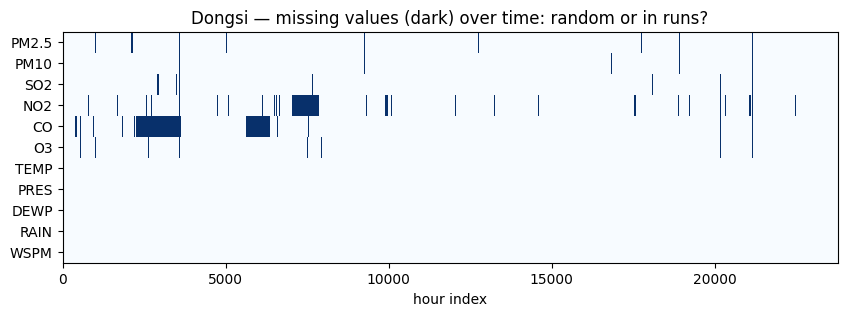

In [ ]:
# missing-value matrix for one station (rows = hours in time order)
one = df[df["station"] == "Dongsi"].sort_values(["year", "month", "day", "hour"])
plt.figure(figsize=(10, 3))
plt.imshow(one[POLLUTANTS + WEATHER].isna().values.T, aspect="auto", interpolation="nearest", cmap="Blues")
plt.yticks(range(len(POLLUTANTS + WEATHER)), POLLUTANTS + WEATHER); plt.xlabel("hour index"); plt.grid(False)
plt.title("Dongsi — missing values (dark) over time: random or in runs?"); plt.show()

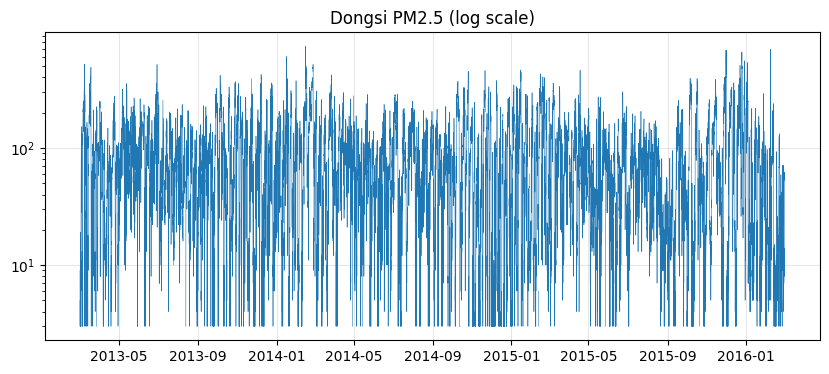

In [ ]:
# the single most useful plot: a time series per station
one_dt = pd.to_datetime(one[["year", "month", "day", "hour"]])
plt.plot(one_dt, one["PM2.5"], lw=.4); plt.yscale("log"); plt.title("Dongsi PM2.5 (log scale)"); plt.show()

## A5 · Consistency: canonical labels  *(slide 21)*

In [ ]:
print(df["station"].value_counts().head(15))
canon = df["station"].str.strip().str.title()
print("\nafter strip + title:", canon.nunique(), "stations")
print("wind directions:", sorted(df["wd"].dropna().unique()))

station
Changping        24501
Huairou          23845
Nongzhanguan     23822
Gucheng          23813
Shunyi           23811
Wanliu           23805
Wanshouxigong    23793
Guanyuan         23789
Dingling         23788
Dongsi           23761
Tiantan          23746
Aotizhongxin     23734
gucheng           1386
CHANGPING         1384
AOTIZHONGXIN      1379
Name: count, dtype: int64

after strip + title: 12 stations
wind directions: ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW', 'e', 'ene', 'ese', 'n', 'ne', 'nne', 'nnw', 'nw', 's', 'se', 'sse', 'ssw', 'sw', 'w', 'wnw', 'wsw']


## A6 · Outliers, stuck sensors and physics checks  *(slides 19 & 20)*

In [ ]:
num = df.copy()
checks = {
    "PM2.5 > PM10 (impossible)": int((num["PM2.5"] > num["PM10"]).sum()),
    "negative concentrations":   int((num[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":       int((num[POLLUTANTS + WEATHER] == -999).sum().sum()),
    "PRES outside 950-1060 hPa": int(((num["PRES"] < 950) | (num["PRES"] > 1060)).sum()),
}
pd.Series(checks, name="rows")

,rows
PM2.5 > PM10 (impossible),22069
negative concentrations,0
sentinel -999 codes,1232
PRES outside 950-1060 hPa,624


In [ ]:
def hampel_flags(s, window=25, k=3.0):
    med = s.rolling(window, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=5).median()
    return (s - med).abs() > k * 1.4826 * mad

def stuck_flags(s, hours=12):
    return s.rolling(hours).std() == 0

res = {}
for st, g in df.assign(station=canon).sort_values(["year", "month", "day", "hour"]).groupby("station"):
    res[st] = {"Hampel spikes": int(hampel_flags(g["PM2.5"]).sum()), "stuck >= 12 h": int(stuck_flags(g["PM2.5"]).sum())}
pd.DataFrame(res).T.sort_values("stuck >= 12 h", ascending=False)

,Hampel spikes,stuck >= 12 h
Huairou,1401,334
Dongsi,1243,56
Wanshouxigong,1123,23
Nongzhanguan,1170,5
Aotizhongxin,1198,1
Changping,1278,0
Dingling,1533,0
Gucheng,1237,0
Guanyuan,1130,0
Shunyi,1153,0


## A7 · Imputation study — single hours vs 24-hour gaps  *(slide 18)*
We hide values we **know** (clean reference = the original training years, demo only) and measure the RMSE of each imputer.

In [ ]:
from sklearn.impute import KNNImputer
piv = train_raw.pivot_table(index="datetime", columns="station", values="NO2")   # hours x stations
target_st = "Dongsi"
truth = piv[target_st]
known = np.flatnonzero(truth.notna().values)

def make_mask(kind):
    m = np.zeros(len(truth), bool)
    if kind == "single hours":
        m[rng.choice(known, len(known) // 10, replace=False)] = True
    else:                                                    # 24-h blocks
        for s0 in rng.choice(known[:-30], 150, replace=False):
            m[s0:s0 + 24] = True
        m &= truth.notna().values
    return m

def evaluate(mask):
    s = truth.mask(mask)
    others = piv.drop(columns=target_st)
    nb = others.mean(axis=1)
    cand = {
        "mean": s.fillna(s.mean()),
        "median": s.fillna(s.median()),
        "time interpolation": s.interpolate(method="time", limit_direction="both"),
        "neighbour stations": s.fillna(nb + (s - nb).mean()),
        "KNN across stations": pd.Series(KNNImputer(n_neighbors=5).fit_transform(piv.assign(**{target_st: s}))[:, list(piv.columns).index(target_st)], index=s.index),
    }
    return {k: np.sqrt(np.mean((v.fillna(s.mean()).values[mask] - truth.values[mask]) ** 2)) for k, v in cand.items()}

t0 = time.perf_counter()
study = pd.DataFrame({kind: evaluate(make_mask(kind)) for kind in ["single hours", "24-h blocks"]}).round(2)
print(f"({time.perf_counter() - t0:.1f} s)  RMSE of NO2 in µg/m³ — lower is better")
study

(35.5 s)  RMSE of NO2 in µg/m³ — lower is better


,single hours,24-h blocks
mean,33.82,31.49
median,34.24,32.13
time interpolation,7.50,29.01
neighbour stations,13.98,13.08
KNN across stations,9.36,9.89


## A8 · Skewness and transformations  *(slides 12 & 25)*

skewness raw:
 PM2.5    1.93
SO2      2.74
CO       2.45
NO2      1.03
O3       1.75
WSPM     1.67
dtype: float64

skewness after log1p:
 PM2.5   -0.33
SO2      0.42
CO      -0.00
NO2     -0.72
O3      -0.59
WSPM     0.29
dtype: float64


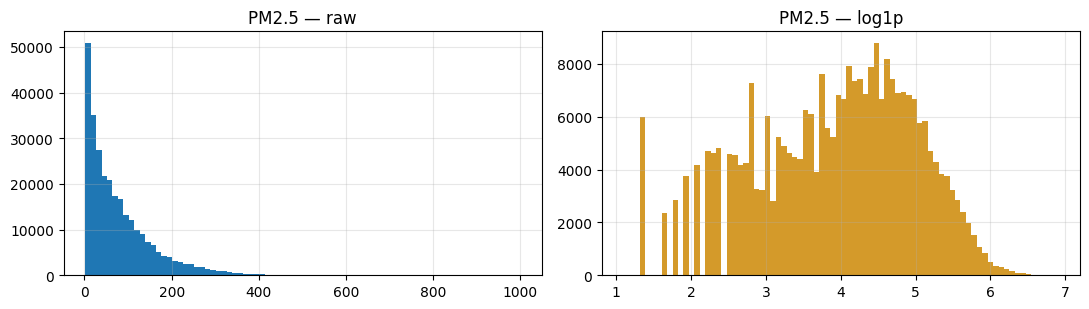

In [ ]:
from sklearn.preprocessing import PowerTransformer
vals = train_raw[["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]].dropna()
print("skewness raw:\n", vals.skew().round(2))
print("\nskewness after log1p:\n", np.log1p(vals).skew().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(vals["PM2.5"], bins=80); ax[0].set_title("PM2.5 — raw")
ax[1].hist(np.log1p(vals["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title("PM2.5 — log1p")
plt.tight_layout(); plt.show()

## A9 · Multicollinearity — VIF  *(slide 22)*

In [ ]:
def vif(frame):
    X = (frame - frame.mean()) / frame.std()
    out = {}
    for c in X.columns:
        Aa = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        coef, *_ = np.linalg.lstsq(Aa, X[c].values, rcond=None)
        resid = X[c].values - Aa @ coef
        out[c] = 1 / max(1 - (1 - (resid ** 2).sum() / ((X[c] - X[c].mean()) ** 2).sum()), 1e-12)
    return pd.Series(out, name="VIF").sort_values(ascending=False).round(2)

vif(train_raw[["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "WSPM"]].dropna().sample(50_000, random_state=0))

,VIF
TEMP,7.83
DEWP,5.75
PRES,3.14
NO2,2.62
CO,2.52
O3,2.23
SO2,1.83
WSPM,1.60


## A10 · Leakage demo — random split vs time split  *(slides 27 & 28)*
Same model, same data, two ways of splitting. The random split lets near-identical neighbouring hours sit on both sides.

In [ ]:
def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

def make_pipeline(model):
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

ref = add_features(train_raw.drop(columns=["datetime"])).dropna(subset=[TARGET]).sort_values("datetime")
ref = ref.iloc[::3]                                   # every 3rd hour keeps the demo fast
X_ref, y_ref = ref[NUM_FEATS + CAT_FEATS], ref[TARGET]
hgb = make_pipeline(HistGradientBoostingRegressor(max_iter=200, random_state=0))
for name, cv in [("random KFold", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit", TimeSeriesSplit(5))]:
    s = cross_val_score(hgb, X_ref, y_ref, cv=cv, scoring="neg_root_mean_squared_error")
    print(f"{name:16s} CV RMSE = {-s.mean():6.2f} ± {s.std():.2f} µg/m³")

random KFold     CV RMSE =  29.70 ± 0.19 µg/m³
TimeSeriesSplit  CV RMSE =  43.11 ± 11.33 µg/m³


## A11 · Template: a leak-free, time-aware pipeline  *(slide 29)*
`make_pipeline` above is the template you adapt in Task 5. Everything that *learns* (imputers, scalers, encoders) lives **inside** it, so it is re-fitted in every fold.

---
# Part B · Week-1 Team Challenge — *The Air-Quality Data Challenge*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The city’s environmental agency merged the exports of its <b>12 monitoring stations</b> (1 Mar 2013 – 29 Feb 2016) for an AI project. On top of the real gaps, the merge introduced errors. Your file <code>beijing_merged_team&lt;N&gt;.csv.gz</code> (created in A3) is your team’s version. <br><b>Goal:</b> deliver a documented, leak-free pipeline for a <b>virtual PM2.5 sensor</b> — estimate PM2.5 from gases, weather, time and station, <b>without PM10</b> (same instrument, down at the same time) — and <b>prove with numbers</b> how much your data work improves it on the untouched test year.</div>

| # | Task | Points |
|---|---|---|
| 1 | Data-quality audit (six dimensions, gap lengths, missingness by station) | 15 |
| 2 | Consistency, validity & timeliness fixes | 15 |
| 3 | Imputation study (≥ 3 imputers incl. one time-aware) | 15 |
| 4 | Outliers: stuck sensors & spikes vs real episodes; transformations | 10 |
| 5 | Leak-free pipeline + `TimeSeriesSplit` CV | 15 |
| 6 | Impact study on the test year | 20 |
| ★ | HPC bonus: parallel per-station cleaning | +10 |
|   | 1-page report + 5-min pitch | 10 |

**Rules:** `test_year` only in Task 6 · justify every decision in one line · keep `SEED` fixed · start from `beijing_merged_team<N>.csv.gz`, not from `train_raw`.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–5 · Day 5 Task 6 (+ bonus) · Days 6–7 report & pitch.

**Hint — what kinds of problems to look for:** label variants, a unit mix-up, a time-zone shift, re-uploaded data, stuck sensors, sentinel codes, physically impossible values, extra drop-outs. *Which station, which column, which period? That is for you to find.*

## Task 1 · Data-quality audit (15 pts)

In [ ]:
df = pd.read_csv(f"beijing_merged_team{TEAM_ID}.csv.gz")

# TODO 1a completeness: % missing per column AND per station; gap-length distribution (see slide 17 code)
# TODO 1b uniqueness: duplicate station-hours (KEY); are duplicates identical or slightly different?
# TODO 1c validity: PM2.5 > PM10, negative values, -999 codes, implausible PRES / TEMP
# TODO 1d accuracy: station medians of each pollutant on a log scale — any station x1000 off? which years?
# TODO 1e timeliness: hour of the mean daily TEMP / O3 peak per station and year — any station shifted?
# TODO 1f consistency: raw station and wd labels

In [ ]:
# Canonical station name used ONLY for auditing/grouping.
# We keep the original `station` column untouched so that
# consistency problems remain visible.
df["station_canon"] = df["station"].astype("string").str.strip().str.title()

# Parsed datetime for temporal audits
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]],
    errors="coerce"
)

In [ ]:
audit_time = df.dropna(subset=["station_canon", "datetime"]).copy()
audit_time = audit_time.sort_values(["station_canon", "datetime"])

expected_hours = pd.date_range(
    audit_time["datetime"].min(),
    audit_time["datetime"].max(),
    freq="h"
)

timestamp_gaps = []

for station, group in audit_time.groupby("station_canon"):
    observed_times = pd.DatetimeIndex(group["datetime"].drop_duplicates())
    missing_times = expected_hours.difference(observed_times)

    timestamp_gaps.append({
        "station": station,
        "observed_timestamps": len(observed_times),
        "missing_timestamps": len(missing_times),
        "first_missing_timestamp": (
            missing_times.min() if len(missing_times) else pd.NaT
        ),
        "last_missing_timestamp": (
            missing_times.max() if len(missing_times) else pd.NaT
        ),
    })

timestamp_gap_report = pd.DataFrame(timestamp_gaps)

display(
    timestamp_gap_report.sort_values(
        "missing_timestamps", ascending=False
    )
)

,station,observed_timestamps,missing_timestamps,first_missing_timestamp,last_missing_timestamp
7,Nongzhanguan,26296,8,2015-12-31 16:00:00,2015-12-31 23:00:00
0,Aotizhongxin,26304,0,NaT,NaT
2,Dingling,26304,0,NaT,NaT
1,Changping,26304,0,NaT,NaT
3,Dongsi,26304,0,NaT,NaT
4,Guanyuan,26304,0,NaT,NaT
5,Gucheng,26304,0,NaT,NaT
6,Huairou,26304,0,NaT,NaT
8,Shunyi,26304,0,NaT,NaT
9,Tiantan,26304,0,NaT,NaT


In [ ]:
issue_log = pd.DataFrame(columns=["dimension", "station", "column", "period", "problem", "rows affected", "fix", "justification"])
# issue_log.loc[len(issue_log)] = ["validity", "all", "TEMP", "all", "-999 sentinel", 123, "set to NaN", "not a measurement"]
issue_log

,dimension,station,column,period,problem,rows affected,fix,justification


In [ ]:
def log_issue(dimension, station, column, period, problem,
              rows_affected, fix="", justification=""):
    global issue_log
    issue_log.loc[len(issue_log)] = [
        dimension, station, column, period,
        problem, int(rows_affected), fix, justification
    ]

### Overall missingness

In [ ]:
AUDIT_COLS = POLLUTANTS + WEATHER + ["wd"]

missing_overall = (
    df[AUDIT_COLS]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_%")
    .to_frame()
)

In [ ]:
print("\nOverall missingness (%):")
display(missing_overall.round(2))


Overall missingness (%):


,missing_%
NO2,5.91
CO,5.73
O3,3.22
SO2,2.21
PM2.5,2.01
PM10,1.46
wd,0.21
DEWP,0.06
PRES,0.06
TEMP,0.06


### Missingness by station

In [ ]:
missing_by_station = (
    df.groupby("station_canon")[AUDIT_COLS]
      .apply(lambda x: x.isna().mean() * 100)
)

In [ ]:
print("\nMissingness by station (%):")
display(missing_by_station.round(2))


Missingness by station (%):


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
station_canon,,,,,,,,,,,,
Aotizhongxin,2.83,2.29,3.02,5.95,6.18,5.54,0.01,0.01,0.01,0.01,0.01,0.04
Changping,2.49,1.85,1.86,4.81,5.11,1.87,0.12,0.12,0.12,0.13,0.12,0.27
Dingling,1.89,1.87,2.03,6.83,6.72,2.87,0.12,0.12,0.12,0.13,0.12,0.28
Dongsi,1.40,0.91,1.32,7.64,10.84,1.24,0.01,0.01,0.01,0.01,0.01,0.03
Guanyuan,1.61,1.10,1.42,4.98,5.82,4.04,0.01,0.01,0.01,0.01,0.01,0.04
Gucheng,1.87,1.05,1.57,5.00,4.84,2.40,0.13,0.12,0.13,0.10,0.12,0.45
Huairou,3.06,2.46,3.18,7.75,4.59,3.73,0.13,0.14,0.14,0.14,0.14,0.54
Nongzhanguan,1.84,1.25,1.29,4.95,3.68,1.48,0.01,0.01,0.01,0.01,0.01,0.03
Shunyi,2.24,1.06,3.31,6.32,6.67,2.19,0.12,0.12,0.14,0.12,0.12,0.76


### Number of missing cells by station

In [ ]:
missing_overall_station = (
    df.groupby("station_canon")[AUDIT_COLS]
      .apply(lambda x: x.isna().mean().mean() * 100)
      .sort_values(ascending=False)
      .rename("overall_missing_%")
      .to_frame()
)

In [ ]:
print("Overall missingness by station:")
display(missing_overall_station.round(2))

Overall missingness by station:


,overall_missing_%
station_canon,
Huairou,2.17
Aotizhongxin,2.16
Wanliu,1.98
Dongsi,1.95
Shunyi,1.93
Dingling,1.93
Tiantan,1.64
Guanyuan,1.59
Changping,1.57


### Gap-length distribution

In [ ]:
gap_records = []

for station, station_df in audit_time.groupby("station_canon"):
    station_df = (
        station_df.sort_values("datetime")
        .drop_duplicates("datetime")
        .reset_index(drop=True)
    )

    for col in AUDIT_COLS:
        missing = station_df[col].isna().to_numpy()
        times = station_df["datetime"]

        # A missing run continues only if the next timestamp is exactly 1 hour later.
        run_start = None

        for i in range(len(station_df)):
            is_missing = bool(missing[i])

            consecutive_to_previous = (
                i > 0
                and times.iloc[i] - times.iloc[i - 1]
                == pd.Timedelta(hours=1)
            )

            if is_missing and run_start is None:
                run_start = i

            elif is_missing and run_start is not None:
                if not consecutive_to_previous:
                    # Close the previous run before starting a new one.
                    gap_records.append({
                        "station": station,
                        "column": col,
                        "start": times.iloc[run_start],
                        "end": times.iloc[i - 1],
                        "gap_length_hours": i - run_start,
                    })
                    run_start = i

            elif not is_missing and run_start is not None:
                gap_records.append({
                    "station": station,
                    "column": col,
                    "start": times.iloc[run_start],
                    "end": times.iloc[i - 1],
                    "gap_length_hours": i - run_start,
                })
                run_start = None

        # Close a run that reaches the end of the station's data.
        if run_start is not None:
            gap_records.append({
                "station": station,
                "column": col,
                "start": times.iloc[run_start],
                "end": times.iloc[-1],
                "gap_length_hours": len(station_df) - run_start,
            })

gap_lengths = pd.DataFrame(gap_records)

display(gap_lengths.head())
display(
    gap_lengths.groupby("column")["gap_length_hours"]
    .agg(["count", "median", "mean", "max"])
    .sort_values("max", ascending=False)
)

,station,column,start,end,gap_length_hours
0,Aotizhongxin,PM2.5,2013-05-02 21:00:00,2013-05-02 21:00:00,1
1,Aotizhongxin,PM2.5,2013-05-16 13:00:00,2013-05-16 13:00:00,1
2,Aotizhongxin,PM2.5,2013-06-07 16:00:00,2013-06-07 16:00:00,1
3,Aotizhongxin,PM2.5,2013-06-25 01:00:00,2013-06-25 01:00:00,1
4,Aotizhongxin,PM2.5,2013-06-26 00:00:00,2013-06-26 00:00:00,1


,count,median,mean,max
column,,,,
CO,3749,1.0,4.829555,1517
NO2,11216,1.0,1.665745,900
SO2,2012,1.0,3.472664,457
O3,3327,1.0,3.058912,429
PM2.5,1919,1.0,3.315268,343
PM10,1519,1.0,3.040816,343
wd,563,1.0,1.198934,13
DEWP,164,1.0,1.121951,7
TEMP,160,1.0,1.112500,7


In [ ]:
print("Gap-length summary:")
display(
    gap_lengths["gap_length_hours"]
    .describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(2)
    .to_frame()
)

Gap-length summary:


,gap_length_hours
count,25119.00
mean,2.65
std,19.03
min,1.00
50%,1.00
75%,1.00
90%,3.00
95%,6.00
99%,23.00
max,1517.00


In [ ]:
# Longest gaps
print("Longest missing-value gaps:")
display(
    gap_lengths
    .sort_values("gap_length_hours", ascending=False)
    .head(20)
)

Longest missing-value gaps:


,station,column,start,end,gap_length_hours
7426,Dongsi,CO,2013-06-11 12:00:00,2013-08-13 16:00:00,1517
5548,Dingling,CO,2013-09-30 19:00:00,2013-11-13 13:00:00,1051
6780,Dongsi,NO2,2014-01-19 09:00:00,2014-02-25 20:00:00,900
7459,Dongsi,CO,2013-11-13 09:00:00,2013-12-17 14:00:00,822
17385,Shunyi,CO,2013-07-13 12:00:00,2013-08-13 16:00:00,749
22668,Wanliu,CO,2013-11-22 15:00:00,2013-12-19 08:00:00,642
22268,Wanliu,NO2,2015-03-30 14:00:00,2015-04-22 09:00:00,548
19105,Tiantan,SO2,2014-05-15 09:00:00,2014-06-03 09:00:00,457
9107,Guanyuan,CO,2013-12-01 00:00:00,2013-12-19 08:00:00,441
22948,Wanliu,O3,2014-01-01 00:00:00,2014-01-18 20:00:00,429


In [ ]:

# Gap distribution by column
gap_by_column = (
    gap_lengths
    .groupby("column")["gap_length_hours"]
    .agg(
        gaps="count",
        mean="mean",
        median="median",
        max="max"
    )
    .sort_values("max", ascending=False)
)

print("Gap statistics by column:")
display(gap_by_column.round(2))

Gap statistics by column:


,gaps,mean,median,max
column,,,,
CO,3749,4.83,1.0,1517
NO2,11216,1.67,1.0,900
SO2,2012,3.47,1.0,457
O3,3327,3.06,1.0,429
PM2.5,1919,3.32,1.0,343
PM10,1519,3.04,1.0,343
wd,563,1.20,1.0,13
DEWP,164,1.12,1.0,7
TEMP,160,1.11,1.0,7


In [ ]:
# Gap distribution by station
gap_by_station = (
    gap_lengths
    .groupby("station")["gap_length_hours"]
    .agg(
        gaps="count",
        mean="mean",
        median="median",
        max="max"
    )
    .sort_values("max", ascending=False)
)

print("Gap statistics by station:")
display(gap_by_station.round(2))

Gap statistics by station:


,gaps,mean,median,max
station,,,,
Dongsi,1563,3.94,1.0,1517
Dingling,2143,2.83,1.0,1051
Shunyi,2776,2.20,1.0,749
Wanliu,2314,2.70,1.0,642
Tiantan,2593,1.99,1.0,457
Guanyuan,1747,2.87,1.0,441
Gucheng,1854,2.53,1.0,349
Aotizhongxin,2041,3.34,1.0,344
Huairou,2622,2.61,1.0,211


# ====================================
# 1b · UNIQUENESS
# ====================================

In [ ]:
# KEY is station + year + month + day + hour
duplicate_mask = df.duplicated(subset=KEY, keep=False)
duplicate_rows = df.loc[duplicate_mask].copy()

print(f"\nDuplicate station-hours: {duplicate_mask.sum():,}")
print(f"Duplicate station-hours / total rows: "
      f"{duplicate_mask.mean() * 100:.3f}%")



Duplicate station-hours: 4,654
Duplicate station-hours / total rows: 1.464%


In [ ]:
# Number of duplicated KEY groups
duplicate_groups = (
    df.loc[duplicate_mask]
      .groupby(KEY, dropna=False)
      .size()
      .sort_values(ascending=False)
)

print(f"Duplicate KEY groups: {len(duplicate_groups):,}")

print("\nLargest duplicate groups:")
display(duplicate_groups.head(20).rename("rows").to_frame())

Duplicate KEY groups: 2,325

Largest duplicate groups:


rows
station      year month day hour      
Changping    2014 12    11  0        3
                            2        3
                        28  20       3
                        26  6        3
NONGZHANGUAN 2014 2     27  18       2
                  7     25  21       2
                  10    31  16       2
             2015 10    2   22       2
Nongzhanguan 2013 3     3   17       2
                        4   13       2
                        11  11       2
                        12  6        2
                        16  9        2
                        18  1        2
                        27  19       2
                  4     3   14       2
                        29  14       2
                  5     5   6        2
NONGZHANGUAN 2014 6     1   3        2
Huairou      2015 10    27  15       2

In [ ]:
# Are duplicated records identical?

if not duplicate_rows.empty:

    duplicate_compare_cols = [
        c for c in df.columns
        if c not in ["station_canon", "datetime"]
    ]

    identical_duplicate_rows = (
        duplicate_rows
        .groupby(KEY, dropna=False)[duplicate_compare_cols]
        .nunique(dropna=False)
        .max(axis=1)
        .eq(1)
    )

    print(
        f"\nDuplicate groups that are completely identical: "
        f"{identical_duplicate_rows.sum():,}"
    )

    print(
        f"Duplicate groups with at least one differing value: "
        f"{(~identical_duplicate_rows).sum():,}"
    )

    # Show examples of non-identical duplicates
    differing_keys = identical_duplicate_rows[
        ~identical_duplicate_rows
    ].index

    if len(differing_keys):
        print("\nExamples of non-identical duplicate station-hours:")
        example = (
            duplicate_rows
            .set_index(KEY)
            .loc[differing_keys[:10]]
            .reset_index()
        )
        display(example)

    log_issue(
        "uniqueness",
        "all",
        "KEY",
        "2013-2015",
        "Duplicate station-hours found",
        duplicate_mask.sum(),
        "deduplicate after distinguishing exact vs conflicting duplicates",
        "Each station-hour should represent one observation."
    )


Duplicate groups that are completely identical: 1,588
Duplicate groups with at least one differing value: 737

Examples of non-identical duplicate station-hours:


,station,year,month,day,hour,No,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station_canon,datetime
0,CHANGPING,2014,12,2,11,15396,44.0,56.0,38.0,56.0,1200.0,15.0,-3.3,1020.0,-21.0,0.0,SSE,1.3,Changping,2014-12-02 11:00:00
1,CHANGPING,2014,12,2,11,15396,44.0,56.0,38.0,56.0,1200.0,16.0,-3.3,1020.0,-21.0,0.0,SSE,1.3,Changping,2014-12-02 11:00:00
2,CHANGPING,2014,12,3,1,15410,54.0,56.0,23.0,42.0,1500.0,18.0,-3.9,1015.0,-26.1,0.0,NNW,2.4,Changping,2014-12-03 01:00:00
3,CHANGPING,2014,12,3,1,15410,54.0,56.0,23.0,42.0,1500.0,19.0,-3.9,1015.0,-26.1,0.0,NNW,2.4,Changping,2014-12-03 01:00:00
4,CHANGPING,2014,12,3,7,15416,9.0,28.0,10.0,25.0,400.0,34.0,-4.5,1019.0,-26.6,0.0,NW,3.0,Changping,2014-12-03 07:00:00
5,CHANGPING,2014,12,3,7,15416,9.0,28.0,10.0,25.0,400.0,33.0,-4.5,1019.0,-26.6,0.0,NW,3.0,Changping,2014-12-03 07:00:00
6,CHANGPING,2014,12,3,20,15429,13.0,82.0,8.0,38.0,400.0,43.0,-2.2,1018.0,-24.7,0.0,WNW,4.0,Changping,2014-12-03 20:00:00
7,CHANGPING,2014,12,3,20,15429,13.0,82.0,8.0,38.0,400.0,42.0,-2.2,1018.0,-24.7,0.0,WNW,4.0,Changping,2014-12-03 20:00:00
8,CHANGPING,2014,12,5,2,15459,7.0,13.0,7.0,15.0,500.0,53.0,-5.5,1024.0,-25.0,0.0,N,1.8,Changping,2014-12-05 02:00:00
9,CHANGPING,2014,12,5,2,15459,7.0,13.0,7.0,15.0,500.0,54.0,-5.5,1024.0,-25.0,0.0,N,1.8,Changping,2014-12-05 02:00:00


# ============================================================
# 1c · VALIDITY
# ============================================================


In [ ]:
validity_checks = {}

validity_checks["PM2.5 > PM10"] = int(
    (df["PM2.5"] > df["PM10"]).sum()
)

validity_checks["negative pollutant values"] = int(
    (df[POLLUTANTS] < 0).sum().sum()
)

validity_checks["-999 sentinel values"] = int(
    (df[POLLUTANTS + WEATHER] == -999).sum().sum()
)

validity_checks["PRES < 950 hPa"] = int(
    (df["PRES"] < 950).sum()
)

validity_checks["PRES > 1060 hPa"] = int(
    (df["PRES"] > 1060).sum()
)

validity_checks["TEMP < -40 °C"] = int(
    (df["TEMP"] < -40).sum()
)

validity_checks["TEMP > 50 °C"] = int(
    (df["TEMP"] > 50).sum()
)

validity_table = pd.Series(
    validity_checks,
    name="rows"
).to_frame()

display(validity_table)

,rows
PM2.5 > PM10,22069
negative pollutant values,0
-999 sentinel values,1232
PRES < 950 hPa,624
PRES > 1060 hPa,0
TEMP < -40 °C,608
TEMP > 50 °C,0


In [ ]:
# ---- Locate PM2.5 > PM10 -------------------------------

pm_relation = df["PM2.5"] > df["PM10"]

if pm_relation.any():
    pm_bad = (
        df.loc[pm_relation]
        .groupby("station_canon")
        .size()
        .sort_values(ascending=False)
        .rename("rows")
        .to_frame()
    )

    print("\nPM2.5 > PM10 by station:")
    display(pm_bad)

    log_issue(
        "validity",
        "all",
        "PM2.5/PM10",
        "2013-2015",
        "PM2.5 exceeds PM10",
        pm_relation.sum(),
        "investigate possible PM2.5/PM10 swaps",
        "PM2.5 is a component of PM10, so PM2.5 > PM10 is physically inconsistent."
    )


PM2.5 > PM10 by station:


,rows
station_canon,
Dingling,2998
Dongsi,2215
Wanliu,1968
Shunyi,1913
Nongzhanguan,1898
Changping,1739
Wanshouxigong,1705
Huairou,1683
Tiantan,1661


In [ ]:
# ---- Sentinel values -------------------------------------

sentinel_mask = df[POLLUTANTS + WEATHER].eq(-999).any(axis=1)

if sentinel_mask.any():
    sentinel_by_col = (
        df[POLLUTANTS + WEATHER]
        .eq(-999)
        .sum()
        .sort_values(ascending=False)
        .rename("rows")
        .to_frame()
    )

    print("\n-999 sentinel values by column:")
    display(sentinel_by_col[sentinel_by_col["rows"] > 0])

    for col in sentinel_by_col.index:
        count = int(sentinel_by_col.loc[col, "rows"])

        if count:
            log_issue(
                "validity",
                "all",
                col,
                "2013-2015",
                "-999 sentinel code",
                count,
                "replace with NaN",
                "-999 is a missing/sentinel code, not a physical measurement."
            )


-999 sentinel values by column:


,rows
PRES,624
TEMP,608


In [ ]:
# ---- Negative values -------------------------------------

negative_by_col = (
    df[POLLUTANTS]
    .lt(0)
    .sum()
)

print("\nNegative pollutant values:")
display(negative_by_col[negative_by_col > 0].rename("rows").to_frame())


Negative pollutant values:


,rows


In [ ]:
# ---- Pressure / temperature -----------------------------

for col, low, high in [
    ("PRES", 950, 1060),
    ("TEMP", -40, 50),
]:

    bad = (df[col] < low) | (df[col] > high)
    bad_count = int(bad.sum())

    print(f"\n{col} outside [{low}, {high}]: {bad_count:,}")

    if bad_count:
        display(
            df.loc[bad]
            .groupby("station_canon")
            .size()
            .sort_values(ascending=False)
            .rename("rows")
            .to_frame()
        )

        log_issue(
            "validity",
            "all",
            col,
            "2013-2015",
            f"Values outside plausible range [{low}, {high}]",
            bad_count,
            "set implausible values to NaN",
            "Values outside the physically plausible range are invalid measurements."
        )


PRES outside [950, 1060]: 624


,rows
station_canon,
Wanshouxigong,64
Aotizhongxin,62
Gucheng,60
Tiantan,57
Shunyi,54
Dingling,52
Guanyuan,49
Dongsi,48
Nongzhanguan,47



TEMP outside [-40, 50]: 608


,rows
station_canon,
Changping,64
Wanshouxigong,59
Dongsi,56
Gucheng,55
Shunyi,53
Huairou,51
Nongzhanguan,48
Wanliu,47
Tiantan,46


# ============================================================
# 1d · ACCURACY
# ============================================================

In [ ]:
# Station medians for pollutants.
# log10 makes a factor-of-1000 problem immediately visible.

station_medians = (
    df.groupby("station_canon")[POLLUTANTS]
      .median()
)

print("\nStation pollutant medians:")
display(station_medians.round(3))


Station pollutant medians:


,PM2.5,PM10,SO2,NO2,CO,O3
station_canon,,,,,,
Aotizhongxin,60.0,91.0,10.0,57.0,900.0,39.841
Changping,47.0,73.0,8.0,36.0,800.0,47.000
Dingling,41.0,60.0,6.0,19.0,600.0,61.000
Dongsi,61.0,88.0,11.0,48.0,1000.0,44.000
Guanyuan,60.0,89.0,9.0,52.0,900.0,40.000
Gucheng,61.0,100.0,8.0,51.0,500.0,45.839
Huairou,48.0,70.0,5.0,27.0,800.0,50.000
Nongzhanguan,60.0,87.0,11.0,53.0,1000.0,44.000
Shunyi,56.0,79.0,5.0,37.0,900.0,43.000


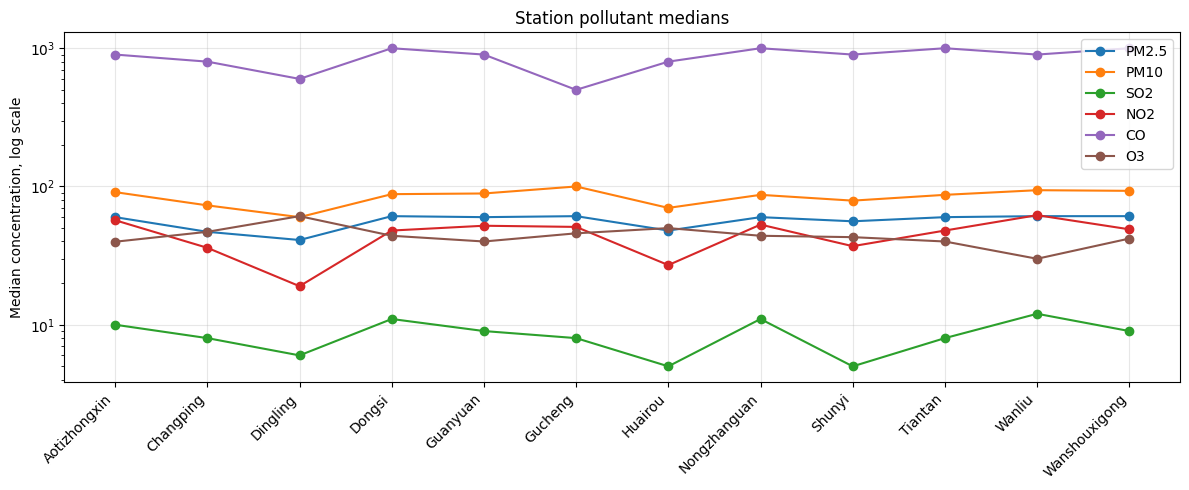

In [ ]:
plt.figure(figsize=(12, 5))

for col in POLLUTANTS:
    plt.plot(
        station_medians.index,
        station_medians[col],
        marker="o",
        label=col
    )

plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Median concentration, log scale")
plt.title("Station pollutant medians")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ---- Accuracy by station AND year ------------------------

median_station_year = (
    df.groupby(["station_canon", "year"])[POLLUTANTS]
      .median()
)

print("\nStation × year pollutant medians:")
display(median_station_year.round(3))


Station × year pollutant medians:


PM2.5   PM10     SO2     NO2      CO      O3
station_canon year                                              
Aotizhongxin  2013   62.0   97.0  14.000  60.000   900.0  34.000
              2014   69.0   98.0  10.000  60.000   900.0  32.000
              2015   55.0   87.0   7.000  53.000   900.0  50.000
              2016   21.0   44.0  13.000  34.000   800.0  46.000
Changping     2013   52.0   74.0  10.926  35.000   800.0  48.000
              2014   50.0   83.0  10.000  38.000   800.0  47.000
              2015   45.5   68.0   4.000  34.000   700.0  47.000
              2016   19.0   44.0   9.000  42.000   700.0  43.000
Dingling      2013   43.0   57.0   6.000  22.000   700.0  56.000
              2014   46.0   68.0   6.000  19.000   600.0  62.000
              2015   39.0   59.0   6.000  18.500   600.0  65.000
              2016   16.0   39.0   8.000  10.000   400.0  66.000
Dongsi        2013   66.0   91.0  15.000  52.000  1100.0  47.000
              2014   66.0   96.0  12.000  51.000  1100.0  44.000
              2015   58.0   85.0   8.000  42.000   900.0  43.000
              2016   22.0   47.0  10.000  36.000   700.0  40.000
Guanyuan      2013   62.0   93.0  12.000  53.000   900.0  44.000
              2014   67.0   97.0  10.000  58.000  1000.0  39.000
              2015   56.0   83.0   6.000  46.000   900.0  41.000
              2016   22.0   45.0  12.000  44.000   800.0  31.000
Gucheng       2013   62.0  100.0   8.000  58.000  1000.0  45.000
              2014   68.0  118.0   9.000  58.000     1.0  44.000
              2015   56.0   91.0   5.000  43.000   900.0  48.000
              2016   30.0   55.0  16.000  31.000  1000.0  44.000
Huairou       2013   49.0   74.0   7.000  30.000   800.0  51.000
              2014   55.0   81.0   6.000  31.000   900.0  57.000
              2015   46.0   65.0   3.000  21.000   700.0  49.000
              2016   20.0   35.0   5.000  21.000   700.0  29.000
Nongzhanguan  2013   63.0   87.0  13.000  54.000  1000.0  42.000
              2014   66.0  103.0  11.000  57.000  1000.0  43.000
              2015   56.0   81.0   8.000  48.000   900.0  48.000
              2016   22.5   39.0  11.000  44.000   700.0  44.000
Shunyi        2013   57.0   80.0   6.854  35.000  1000.0  46.053
              2014   62.0   92.0   7.000  40.000   900.0  43.000
              2015   53.0   74.0   3.000  37.000   800.0  39.000
              2016   22.0   34.0   7.000  29.000   600.0  42.000
Tiantan       2013   64.0   93.0   9.000  49.000  1000.0  37.000
              2014   66.0   96.0   9.000  50.000  1000.0  39.000
              2015   55.0   79.0   6.000  44.000   900.0  44.000
              2016   27.0   51.0   9.000  45.000   800.0  39.000
Wanliu        2013   70.0   98.0  15.000  65.285  1000.0  35.000
              2014   66.0  112.0  13.000  70.000   900.0  24.000
              2015   55.0   83.0   8.000  52.000   900.0  32.000
              2016   23.0   42.0  14.000  50.000  1000.0  31.000
Wanshouxigong 2013   65.0   95.0  11.000  52.000  1200.0  40.912
              2014   67.0  105.0   9.000  55.000  1100.0  41.000
              2015   56.0   86.0   6.000  44.000   900.0  46.000
              2016   29.0   48.0  13.000  39.000   900.0  37.000

In [ ]:
# Detect unusually large year-to-year changes.
# A ratio > 100 or < 1/100 is a strong unit-mix-up candidate.

accuracy_records = []

for st in STATIONS:
    for col in POLLUTANTS:

        series = (
            median_station_year.loc[st, col]
            if st in median_station_year.index.get_level_values(0)
            else pd.Series(dtype=float)
        )

        if series.empty:
            continue

        for year, value in series.items():

            if pd.isna(value) or value <= 0:
                continue

            other_years = series.drop(index=year)
            other_years = other_years[other_years > 0]

            if other_years.empty:
                continue

            reference = other_years.median()
            ratio = value / reference

            accuracy_records.append({
                "station": st,
                "column": col,
                "year": year,
                "median": value,
                "reference_median": reference,
                "ratio": ratio
            })

accuracy_check = pd.DataFrame(accuracy_records)

print("\nLargest station/year median deviations:")
display(
    accuracy_check
    .assign(abs_log_ratio=lambda x: np.abs(np.log10(x["ratio"])))
    .sort_values("abs_log_ratio", ascending=False)
    .head(20)
)


Largest station/year median deviations:


,station,column,year,median,reference_median,ratio,abs_log_ratio
137,Gucheng,CO,2014,1.0,1000.0,0.001000,3.000000
75,Dongsi,PM2.5,2016,22.0,66.0,0.333333,0.477121
3,Aotizhongxin,PM2.5,2016,21.0,62.0,0.338710,0.470172
243,Wanliu,PM2.5,2016,23.0,66.0,0.348485,0.457816
99,Guanyuan,PM2.5,2016,22.0,62.0,0.354839,0.449969
171,Nongzhanguan,PM2.5,2016,22.5,63.0,0.357143,0.447158
51,Dingling,PM2.5,2016,16.0,43.0,0.372093,0.429348
27,Changping,PM2.5,2016,19.0,50.0,0.380000,0.420216
195,Shunyi,PM2.5,2016,22.0,57.0,0.385965,0.413452
34,Changping,SO2,2015,4.0,10.0,0.400000,0.397940


In [ ]:
# Explicit CO unit investigation.
co_year_station = (
    df.groupby(["station_canon", "year"])["CO"]
      .median()
      .unstack()
)

print("\nCO median by station/year:")
display(co_year_station.round(4))


CO median by station/year:


year,2013,2014,2015,2016
station_canon,,,,
Aotizhongxin,900.0,900.0,900.0,800.0
Changping,800.0,800.0,700.0,700.0
Dingling,700.0,600.0,600.0,400.0
Dongsi,1100.0,1100.0,900.0,700.0
Guanyuan,900.0,1000.0,900.0,800.0
Gucheng,1000.0,1.0,900.0,1000.0
Huairou,800.0,900.0,700.0,700.0
Nongzhanguan,1000.0,1000.0,900.0,700.0
Shunyi,1000.0,900.0,800.0,600.0


In [ ]:
# Find a likely x1000 anomaly automatically.
for st in co_year_station.index:

    row = co_year_station.loc[st].dropna()

    for year in row.index:

        value = row.loc[year]

        reference = row.drop(index=year).median()

        if reference > 0:

            ratio = value / reference

            if ratio < 0.01 or ratio > 100:

                affected = int(
                    (
                        (df["station_canon"] == st) &
                        (df["year"] == year) &
                        df["CO"].notna()
                    ).sum()
                )

                log_issue(
                    "accuracy",
                    st,
                    "CO",
                    str(year),
                    f"CO median differs by factor {ratio:.1f} from station baseline",
                    affected,
                    "convert unit to the common CO unit",
                    "A factor-of-1000 shift is characteristic of a mg/m³ vs µg/m³ unit error."
                )

# ============================================================
# 1e · TIMELINESS
# ============================================================

In [ ]:
# Compute mean TEMP and O3 for every station/year/hour.
hourly_profile = (
    df.groupby(["station_canon", "year", "hour"])[["TEMP", "O3"]]
      .mean()
)

# Peak hour for TEMP and O3 for every station/year
peak_records = []

for (st, year), g in hourly_profile.groupby(level=[0, 1]):

    g = g.reset_index()

    for col in ["TEMP", "O3"]:

        valid = g.dropna(subset=[col])

        if valid.empty:
            continue

        peak_row = valid.loc[valid[col].idxmax()]

        peak_records.append({
            "station": st,
            "year": year,
            "variable": col,
            "peak_hour": int(peak_row["hour"]),
            "peak_mean": float(peak_row[col])
        })

peak_hours = pd.DataFrame(peak_records)

print("\nMean daily-profile peak hour by station/year:")
display(
    peak_hours
    .sort_values(["variable", "station", "year"])
)


Mean daily-profile peak hour by station/year:


,station,year,variable,peak_hour,peak_mean
1,Aotizhongxin,2013,O3,16,95.472573
3,Aotizhongxin,2014,O3,16,97.943787
5,Aotizhongxin,2015,O3,16,114.176471
7,Aotizhongxin,2016,O3,15,62.762712
9,Changping,2013,O3,16,105.050819
...,...,...,...,...,...
86,Wanliu,2016,TEMP,15,3.655000
88,Wanshouxigong,2013,TEMP,14,20.620847
90,Wanshouxigong,2014,TEMP,15,18.898087
92,Wanshouxigong,2015,TEMP,14,17.673765



TEMP peak hour:


year,2013,2014,2015,2016
station,,,,
Aotizhongxin,14,14,16,15
Changping,14,14,15,15
Dingling,11,14,15,15
Dongsi,15,14,17,15
Guanyuan,14,14,15,16
Gucheng,14,14,15,15
Huairou,13,14,16,15
Nongzhanguan,15,13,8,15
Shunyi,14,12,16,15


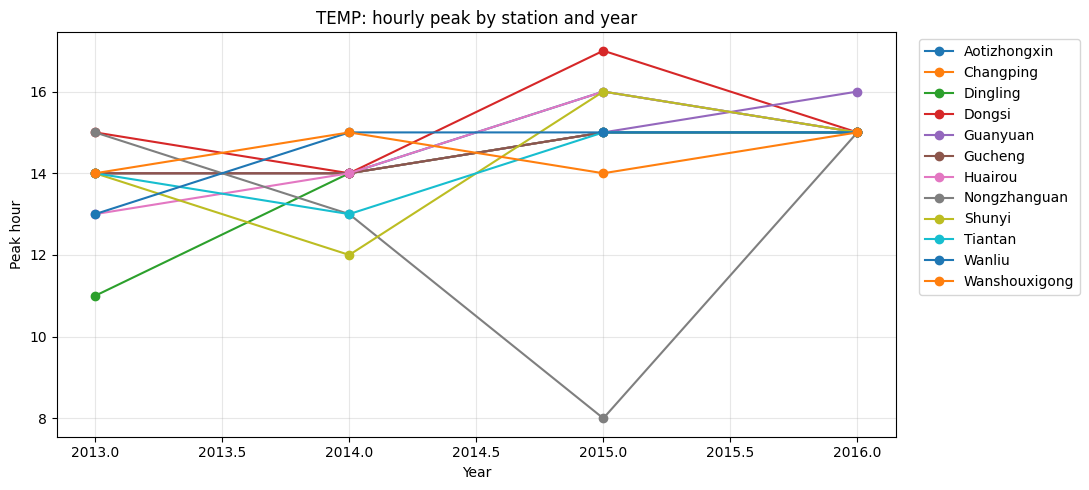


O3 peak hour:


year,2013,2014,2015,2016
station,,,,
Aotizhongxin,16,16,16,15
Changping,16,16,16,15
Dingling,16,16,16,15
Dongsi,16,16,16,15
Guanyuan,16,15,16,15
Gucheng,16,16,16,14
Huairou,16,16,16,14
Nongzhanguan,15,16,8,15
Shunyi,16,16,16,15


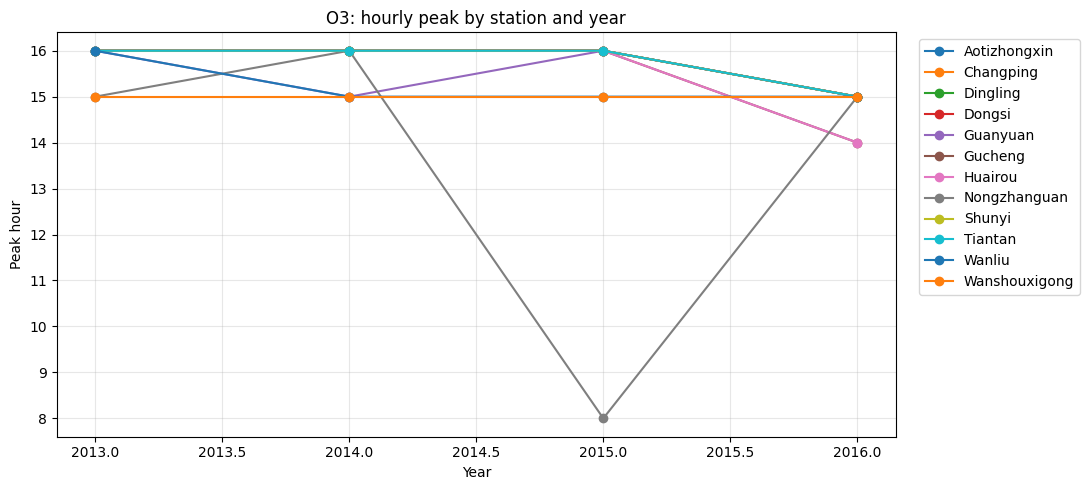

In [ ]:
# Pivot for easier visual detection of shifts
for col in ["TEMP", "O3"]:

    p = (
        peak_hours[peak_hours["variable"] == col]
        .pivot(index="station", columns="year", values="peak_hour")
    )

    print(f"\n{col} peak hour:")
    display(p)

    plt.figure(figsize=(11, 5))

    for st in p.index:
        plt.plot(
            p.columns,
            p.loc[st],
            marker="o",
            label=st
        )

    plt.xlabel("Year")
    plt.ylabel("Peak hour")
    plt.title(f"{col}: hourly peak by station and year")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [ ]:
# Compare each station/year against its own other-year median.
# A persistent ~8-hour displacement is a strong timezone signal.

for col in ["TEMP", "O3"]:

    p = (
        peak_hours[peak_hours["variable"] == col]
        .pivot(index="station", columns="year", values="peak_hour")
    )

    for st in p.index:

        row = p.loc[st].dropna()

        if len(row) < 2:
            continue

        baseline = row.median()

        for year, peak in row.items():

            # Circular hour difference
            diff = ((peak - baseline + 12) % 24) - 12

            if abs(diff) >= 6:

                affected = int(
                    (
                        (df["station_canon"] == st) &
                        (df["year"] == year)
                    ).sum()
                )

                log_issue(
                    "timeliness",
                    st,
                    "datetime",
                    str(year),
                    f"{col} daily-profile peak shifted by {diff:+.0f} h",
                    affected,
                    "shift timestamps back to Beijing local time",
                    "A consistent multi-hour displacement indicates a timezone/timestamp alignment error."
                )

# ============================================================
# 1f · CONSISTENCY
# ============================================================

In [ ]:
# ---- Raw station labels -----------------------------------

raw_station_counts = (
    df["station"]
    .value_counts(dropna=False)
    .rename("rows")
    .to_frame()
)

print("\nRaw station labels:")
display(raw_station_counts)


Raw station labels:


,rows
station,
Changping,24501
Huairou,23845
Nongzhanguan,23822
Gucheng,23813
Shunyi,23811
Wanliu,23805
Wanshouxigong,23793
Guanyuan,23789
Dingling,23788


In [ ]:
print(f"\nRaw distinct station labels: {df['station'].nunique(dropna=False)}")
print(f"Canonical distinct station labels: {df['station_canon'].nunique(dropna=False)}")


Raw distinct station labels: 36
Canonical distinct station labels: 12


In [ ]:
# Identify non-canonical station spellings
station_variants = (
    df.loc[df["station"] != df["station_canon"],
           ["station", "station_canon"]]
    .value_counts()
    .rename("rows")
    .reset_index()
)

print("\nStation label variants:")
display(station_variants)


Station label variants:


,station,station_canon,rows
0,gucheng,Gucheng,1386
1,CHANGPING,Changping,1384
2,AOTIZHONGXIN,Aotizhongxin,1379
3,dongsi,Dongsi,1374
4,shunyi,Shunyi,1371
5,wanshouxigong,Wanshouxigong,1363
6,tiantan,Tiantan,1356
7,wanliu,Wanliu,1349
8,TIANTAN,Tiantan,1341
9,guanyuan,Guanyuan,1334


In [ ]:
for _, row in station_variants.iterrows():

    log_issue(
        "consistency",
        row["station_canon"],
        "station",
        "2013-2015",
        f"Non-canonical station label: {repr(row['station'])}",
        row["rows"],
        "strip whitespace and normalize case",
        "Station identifiers should use one canonical spelling."
    )

In [ ]:
# ---- Wind direction labels --------------------------------

wd_counts = (
    df["wd"]
    .value_counts(dropna=False)
    .rename("rows")
    .to_frame()
)

print("\nRaw wind-direction labels:")
display(wd_counts)


Raw wind-direction labels:


,rows
wd,
NE,29672
ENE,26039
N,23968
E,23056
NW,22510
SW,20683
NNE,20474
WNW,19796
NNW,18551


In [ ]:
valid_wd = set(WD)

invalid_wd_mask = (
    df["wd"].notna() &
    ~df["wd"].isin(valid_wd)
)

print(f"\nInvalid/non-canonical wind-direction rows: " f"{invalid_wd_mask.sum():,}")


Invalid/non-canonical wind-direction rows: 6,357


In [ ]:
if invalid_wd_mask.any():

    print("\nExamples:")
    display(
        df.loc[invalid_wd_mask, "wd"]
        .value_counts()
        .rename("rows")
        .to_frame()
    )

    log_issue(
        "consistency",
        "all",
        "wd",
        "2013-2015",
        "Lower-case/non-canonical wind-direction labels",
        invalid_wd_mask.sum(),
        "normalize wind-direction labels to uppercase",
        "Wind directions are categorical and should use one canonical representation."
    )


Examples:


,rows
wd,
ne,598
ene,522
n,476
nw,474
e,448
nne,440
wnw,423
sw,414
nnw,386


# ============================================================
# SUMMARY
# ============================================================

In [ ]:
issue_log = issue_log.sort_values(
    ["dimension", "station", "column", "period"]
).reset_index(drop=True)

display(issue_log)

print("Issue counts by quality dimension:")
display(
    issue_log.groupby("dimension")
    .agg(
        issues=("problem", "count"),
        rows_affected=("rows affected", "sum")
    )
    .sort_values("rows_affected", ascending=False)
)

,dimension,station,column,period,problem,rows affected,fix,justification
0,accuracy,Gucheng,CO,2014,CO median differs by factor 0.0 from station b...,8633,convert unit to the common CO unit,A factor-of-1000 shift is characteristic of a ...
1,consistency,Aotizhongxin,station,2013-2015,Non-canonical station label: 'AOTIZHONGXIN',1379,strip whitespace and normalize case,Station identifiers should use one canonical s...
2,consistency,Aotizhongxin,station,2013-2015,Non-canonical station label: 'aotizhongxin ',1308,strip whitespace and normalize case,Station identifiers should use one canonical s...
3,consistency,Changping,station,2013-2015,Non-canonical station label: 'CHANGPING',1384,strip whitespace and normalize case,Station identifiers should use one canonical s...
4,consistency,Changping,station,2013-2015,Non-canonical station label: 'changping ',1294,strip whitespace and normalize case,Station identifiers should use one canonical s...
5,consistency,Dingling,station,2013-2015,Non-canonical station label: 'DINGLING',1331,strip whitespace and normalize case,Station identifiers should use one canonical s...
6,consistency,Dingling,station,2013-2015,Non-canonical station label: 'dingling ',1326,strip whitespace and normalize case,Station identifiers should use one canonical s...
7,consistency,Dongsi,station,2013-2015,Non-canonical station label: 'dongsi ',1374,strip whitespace and normalize case,Station identifiers should use one canonical s...
8,consistency,Dongsi,station,2013-2015,Non-canonical station label: 'DONGSI',1291,strip whitespace and normalize case,Station identifiers should use one canonical s...
9,consistency,Guanyuan,station,2013-2015,Non-canonical station label: 'guanyuan ',1334,strip whitespace and normalize case,Station identifiers should use one canonical s...


Issue counts by quality dimension:


,issues,rows_affected
dimension,,
consistency,25,38119
validity,5,24533
timeliness,2,17592
accuracy,1,8633
uniqueness,1,4654


## Task 2 · Consistency, validity & timeliness fixes (15 pts)
Write **one function** `clean_basic(df)` you could apply to next month's export. It should at least: canonicalise `station` and `wd`; fix the unit problem; undo the time-zone shift; set sentinel codes and impossible values to NaN (or repair the swap); flag stuck-sensor runs as NaN; resolve duplicate station-hours; build `datetime`; sort by station and time.

In [ ]:
def detect_stuck_runs(
    data,
    value_col="PM2.5",
    min_hours=12
):
    """
    Return a Boolean Series marking values belonging to runs of
    identical, non-missing readings at consecutive hourly timestamps.

    The returned Series is aligned to data.index.
    """
    flags = pd.Series(False, index=data.index)

    required = {"station", "datetime", value_col}
    missing_cols = required.difference(data.columns)

    if missing_cols:
        raise ValueError(f"Missing columns: {sorted(missing_cols)}")

    for _, group in data.groupby("station", dropna=False):
        group = group.sort_values("datetime")
        values = group[value_col]
        times = group["datetime"]

        # A new run starts when the value changes, the value is missing,
        # or the timestamp is not exactly one hour after the previous row.
        same_as_previous = (
            values.eq(values.shift())
            & values.notna()
            & times.diff().eq(pd.Timedelta(hours=1))
        )

        run_starts = ~same_as_previous
        run_ids = run_starts.cumsum()

        run_lengths = (
            group.assign(_run_id=run_ids.to_numpy())
            .groupby("_run_id")[value_col]
            .transform("size")
        )

        # Ignore missing-value runs; flag actual repeated measurements.
        local_flags = (
            values.notna()
            & run_lengths.ge(min_hours)
        )

        flags.loc[group.index] = local_flags.to_numpy()

    return flags

In [ ]:
def clean_basic(d):
    """Clean the merged training export without using the unt
Task 2 · Consistency, validity & timeliness fixes (15 pts)
Write one function clean_basic(df) you could apply to next month's export. It should at least: canonicalise station and wd; fix the unit problem; undo the time-zone shift; set sentinel codes and impossible values$0ouched test year."""

    d = d.copy()
    original_rows = len(d)
    decisions = []

    # 1. Canonicalize station and wind-direction labels
    d["station"] = (
        d["station"]
        .astype("string")
        .str.strip()
        .str.title()
    )

    d["wd"] = (
        d["wd"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    d.loc[~d["station"].isin(STATIONS), "station"] = pd.NA
    d.loc[~d["wd"].isin(WD), "wd"] = pd.NA

    decisions.append(
        "Station names were stripped and title-cased; "
        "wind-direction labels were stripped and upper-cased."
    )

    # 2. Convert sentinel and impossible values to NaN
    for col in POLLUTANTS + WEATHER:
        d.loc[d[col] == -999, col] = np.nan

    for col in POLLUTANTS + ["RAIN", "WSPM"]:
        d.loc[d[col] < 0, col] = np.nan

    d.loc[
        (d["PRES"] < 950) | (d["PRES"] > 1060),
        "PRES"
    ] = np.nan

    d.loc[
        (d["TEMP"] < -50) | (d["TEMP"] > 60),
        "TEMP"
    ] = np.nan

    decisions.append(
        "Sentinel codes, negative concentrations, and physically "
        "impossible pressure/temperature values were set to NaN."
    )

    # 3. Detect and repair the factor-1000 CO unit error
    co_medians = (
        d.groupby(["station", "year"])["CO"]
        .median()
    )

    unit_fixes = []

    for station in STATIONS:

        if station in co_medians.index.get_level_values(0):
            station_values = co_medians.loc[station]
        else:
            station_values = pd.Series(dtype=float)

        if station_values.empty:
            continue

        reference = station_values[
            station_values > 0
        ].median()

        for year, value in station_values.items():

            if (
                pd.notna(value)
                and value > 0
                and reference > 0
                and value / reference < 0.01
            ):
                mask = (
                    (d["station"] == station)
                    & (d["year"] == year)
                )

                d.loc[mask, "CO"] = (
                    d.loc[mask, "CO"] * 1000
                )

                unit_fixes.append(
                    f"{station}, {int(year)}: CO multiplied by 1000"
                )

    if unit_fixes:
        decisions.append(
            "CO unit correction: " + "; ".join(unit_fixes)
        )
    else:
        decisions.append(
            "No factor-1000 CO unit anomaly was detected."
        )

    # 4. Create datetime using only date/time columns
    # Important: station must not be passed to pd.to_datetime().
    d["datetime"] = pd.to_datetime(
        d[["year", "month", "day", "hour"]],
        errors="coerce"
    )

    # 5. Stuck-sensor detection must run after datetime has been corrected.
    stuck_mask = detect_stuck_runs(
        d,
        value_col="PM2.5",
        min_hours=12
    )

    stuck_count = int(stuck_mask.sum())

    if stuck_count:
        d.loc[stuck_mask, "PM2.5"] = np.nan
        decisions.append(
            f"Set {stuck_count:,} PM2.5 values from repeated hourly "
            "sensor runs (at least 12 consecutive hours) to NaN."
        )
    else:
        decisions.append("No PM2.5 stuck runs of at least 12 hours detected.")

    # 6. Detect and correct the 2015 time-zone shift
    profile = (
        d.groupby(
            ["station", "year", "hour"]
        )[["TEMP", "O3"]]
        .mean()
    )

    shift_scores = {}

    for station in STATIONS:

        score_parts = []

        for col in ["TEMP", "O3"]:

            try:
                station_profile = (
                    profile[col]
                    .loc[station]
                    .reset_index()
                )

                peak_rows = station_profile.loc[
                    station_profile
                    .groupby("year")[col]
                    .idxmax()
                ]

                peaks = (
                    peak_rows
                    .set_index("year")["hour"]
                )

                if 2015 in peaks.index and len(peaks) >= 3:

                    baseline = (
                        peaks
                        .drop(index=2015)
                        .median()
                    )

                    difference = abs(
                        (
                            float(peaks.loc[2015])
                            - baseline
                            + 12
                        ) % 24 - 12
                    )

                    score_parts.append(difference)

            except (KeyError, ValueError):
                continue

        if score_parts:
            shift_scores[station] = float(
                np.mean(score_parts)
            )

    if shift_scores:
        shifted_station = max(
            shift_scores,
            key=shift_scores.get
        )
        shifted_score = shift_scores[shifted_station]
    else:
        shifted_station = None
        shifted_score = 0.0

    if (
        shifted_station is not None
        and shifted_score >= 4
    ):
        mask = (
            (d["station"] == shifted_station)
            & (d["year"] == 2015)
        )

        shifted_datetime = (
            d.loc[mask, "datetime"]
            + pd.Timedelta(hours=8)
        )

        d.loc[mask, "datetime"] = shifted_datetime

        d.loc[
            mask,
            ["year", "month", "day", "hour"]
        ] = np.column_stack([
            shifted_datetime.dt.year,
            shifted_datetime.dt.month,
            shifted_datetime.dt.day,
            shifted_datetime.dt.hour
        ])

        decisions.append(
            f"{shifted_station}, 2015: timestamps shifted "
            f"forward by 8 hours; estimated peak deviation "
            f"was {shifted_score:.1f} hours."
        )
    else:
        decisions.append(
            "No reliable time-zone shift was detected."
        )

    # 7. Repair PM2.5/PM10 column swaps
    swap_mask = (
        d["PM2.5"].notna()
        & d["PM10"].notna()
        & (d["PM2.5"] > d["PM10"])
    )

    number_of_swaps = int(swap_mask.sum())

    d.loc[
        swap_mask,
        ["PM2.5", "PM10"]
    ] = d.loc[
        swap_mask,
        ["PM10", "PM2.5"]
    ].to_numpy()

    decisions.append(
        f"Repaired {number_of_swaps:,} PM2.5/PM10 column swaps."
    )

    # 8. Detect stuck PM2.5 sensor runs
    d = (
        d.sort_values(
            ["station", "datetime"]
        )
        .reset_index(drop=True)
    )

    stuck_mask = pd.Series(
        False,
        index=d.index
    )

    for station, index_values in d.groupby(
        "station",
        sort=False
    ).groups.items():

        pm25_values = d.loc[
            index_values,
            "PM2.5"
        ]

        same_as_previous = (
            pm25_values.eq(pm25_values.shift())
            & pm25_values.notna()
        )

        run_id = same_as_previous.ne(
            same_as_previous.shift(
                fill_value=False
            )
        ).cumsum()

        run_lengths = (
            same_as_previous
            .groupby(run_id)
            .transform("size")
        )

        stuck_mask.loc[index_values] = (
            same_as_previous
            & (run_lengths >= 11)
        )

    number_of_stuck_values = int(
        stuck_mask.sum()
    )

    d.loc[
        stuck_mask,
        "PM2.5"
    ] = np.nan

    decisions.append(
        f"Set {number_of_stuck_values:,} stuck-sensor "
        "PM2.5 readings to NaN."
    )

    # Count completeness before removing duplicate station-hours.
    value_cols = [
        c for c in d.columns
        if c not in KEY + ["datetime"]
    ]

    d["_observed_fields"] = d[value_cols].notna().sum(axis=1)

    duplicate_mask = d.duplicated(subset=KEY, keep=False)
    duplicate_rows_before = int(duplicate_mask.sum())

    # Count station-hour groups that have conflicting values.
    conflicting_groups = 0

    if duplicate_mask.any():
        for _, group in d.loc[duplicate_mask].groupby(
            KEY, dropna=False, sort=False
        ):
            if len(group[value_cols].drop_duplicates()) > 1:
                conflicting_groups += 1

    # Prefer the row with the most observed fields.
    # Stable sorting makes the tie-break deterministic.
    d = (
        d.sort_values(
            ["_observed_fields"],
            ascending=False,
            kind="mergesort"
        )
        .drop_duplicates(subset=KEY, keep="first")
        .drop(columns="_observed_fields")
        .sort_values(["station", "datetime"], kind="mergesort")
        .reset_index(drop=True)
    )

    decisions.append(
        f"Resolved {duplicate_rows_before:,} rows belonging to duplicate "
        f"station-hours; {conflicting_groups:,} duplicate groups had "
        "conflicting values. Kept the most complete row; stable input "
        "order breaks ties."
    )

    # 9. Remove duplicate station-hours
    duplicate_key = [
        "station",
        "year",
        "month",
        "day",
        "hour"
    ]

    d["_observed_fields"] = (
        d[POLLUTANTS + WEATHER + ["wd"]]
        .notna()
        .sum(axis=1)
    )

    duplicate_rows_before_cleaning = int(
        d.duplicated(
            duplicate_key,
            keep=False
        ).sum()
    )

    d = (
        d.sort_values(
            duplicate_key + ["_observed_fields"],
            ascending=[
                True,
                True,
                True,
                True,
                True,
                False
            ]
        )
        .drop_duplicates(
            duplicate_key,
            keep="first"
        )
        .drop(columns="_observed_fields")
    )

    removed_rows = original_rows - len(d)

    decisions.append(
        f"Removed {removed_rows:,} duplicate rows and kept "
        "the most complete record for each station-hour."
    )

    # 10. Rebuild datetime correctly and sort the result
    # Do not use d[KEY] here because KEY includes station.
    d["datetime"] = pd.to_datetime(
        d[["year", "month", "day", "hour"]],
        errors="coerce"
    )

    d = (
        d.sort_values(
            ["station", "datetime"]
        )
        .reset_index(drop=True)
    )

    d.attrs["cleaning_decisions"] = decisions
    d.attrs[
        "duplicate_rows_before_deduplication"
    ] = duplicate_rows_before_cleaning

    return d

In [ ]:
# Run the cleaning function on the merged training export
df_clean = clean_basic(df)

assert df_clean["datetime"].notna().all(), "Some timestamps could not be parsed."
assert df_clean["station"].dropna().isin(STATIONS).all(), "Unexpected station label."
assert df_clean["wd"].dropna().isin(WD).all(), "Unexpected wind-direction label."
assert not df_clean.duplicated(KEY).any(), "Duplicate station-hours remain."

sentinel_cells = int(
    df_clean[POLLUTANTS + WEATHER].eq(-999).sum().sum()
)

negative_concentrations = int(
    df_clean[POLLUTANTS].lt(0).sum().sum()
)

print("Rows in merged export:", f"{len(df):,}")
print("Rows after basic cleaning:", f"{len(df_clean):,}")
print("Rows removed:", f"{len(df) - len(df_clean):,}")
print("Sentinel cells remaining:", sentinel_cells)
print("Negative pollutant concentrations remaining:", negative_concentrations)
print("Duplicate station-hours remaining:", int(df_clean.duplicated(KEY).sum()))

assert sentinel_cells == 0, "Sentinel values remain."
assert negative_concentrations == 0, "Negative pollutant concentrations remain."

print("=" * 70)
print("TASK 2 — CONSISTENCY, VALIDITY AND TIMELINESS FIXES")
print("=" * 70)

print(f"\nRows before cleaning: {len(df):,}")
print(f"Rows after cleaning:  {len(df_clean):,}")
print(
    f"Rows removed:         "
    f"{len(df) - len(df_clean):,}"
)

print(
    f"\nStations after cleaning: "
    f"{df_clean['station'].nunique(dropna=True)}"
)

print(
    "Duplicate station-hours remaining:",
    int(df_clean.duplicated(KEY).sum())
)

print("\nCleaning decisions:")
for decision in df_clean.attrs["cleaning_decisions"]:
    print("-", decision)

# Correct post-cleaning validation

print("\nPost-cleaning validation:")

invalid_station_count = int(
    (
        ~df_clean["station"].isin(STATIONS)
    ).sum()
)

invalid_wind_count = int(
    (
        df_clean["wd"].notna()
        & ~df_clean["wd"].isin(WD)
    ).sum()
)

sentinel_count = int(
    (
        df_clean[POLLUTANTS + WEATHER] == -999
    ).sum().sum()
)

pm25_greater_pm10_count = int(
    (
        df_clean["PM2.5"] > df_clean["PM10"]
    ).sum()
)

# Negative pollutant concentrations are invalid.
# Negative TEMP and DEWP values are valid during winter.
negative_pollutant_count = int(
    (
        df_clean[POLLUTANTS] < 0
    ).sum().sum()
)

negative_rain_count = int(
    (
        df_clean["RAIN"] < 0
    ).sum()
)

negative_wspm_count = int(
    (
        df_clean["WSPM"] < 0
    ).sum()
)

datetime_failure_count = int(
    df_clean["datetime"].isna().sum()
)

print(
    "Invalid station labels:",
    invalid_station_count
)

print(
    "Invalid wind-direction labels:",
    invalid_wind_count
)

print(
    "Remaining sentinel cells:",
    sentinel_count
)

print(
    "Remaining PM2.5 > PM10 values:",
    pm25_greater_pm10_count
)

print(
    "Remaining negative pollutant values:",
    negative_pollutant_count
)

print(
    "Remaining negative RAIN values:",
    negative_rain_count
)

print(
    "Remaining negative WSPM values:",
    negative_wspm_count
)

print(
    "Datetime parsing failures:",
    datetime_failure_count
)

print("\nCleaned-data preview:")
display(df_clean.head())

Rows in merged export: 317,970
Rows after basic cleaning: 315,640
Rows removed: 2,330
Sentinel cells remaining: 0
Negative pollutant concentrations remaining: 0
Duplicate station-hours remaining: 0
TASK 2 — CONSISTENCY, VALIDITY AND TIMELINESS FIXES

Rows before cleaning: 317,970
Rows after cleaning:  315,640
Rows removed:         2,330

Stations after cleaning: 12
Duplicate station-hours remaining: 0

Cleaning decisions:
- Station names were stripped and title-cased; wind-direction labels were stripped and upper-cased.
- Sentinel codes, negative concentrations, and physically impossible pressure/temperature values were set to NaN.
- CO unit correction: Gucheng, 2014: CO multiplied by 1000
- Set 641 PM2.5 values from repeated hourly sensor runs (at least 12 consecutive hours) to NaN.
- Nongzhanguan, 2015: timestamps shifted forward by 8 hours; estimated peak deviation was 7.0 hours.
- Repaired 21,907 PM2.5/PM10 column swaps.
- Set 239 stuck-sensor PM2.5 readings to NaN.
- Resolved 4,65

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,station_canon,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,Aotizhongxin,2013-03-01 04:00:00


,Before cleaning,After cleaning
hour,,
0,9.973674,11.307038
1,10.437297,10.844698
2,10.389596,10.405075
3,8.646354,10.031714
4,7.540349,9.612924
5,8.872115,9.390851
6,8.366028,9.696249
7,12.418386,10.627498
8,12.240759,11.953473


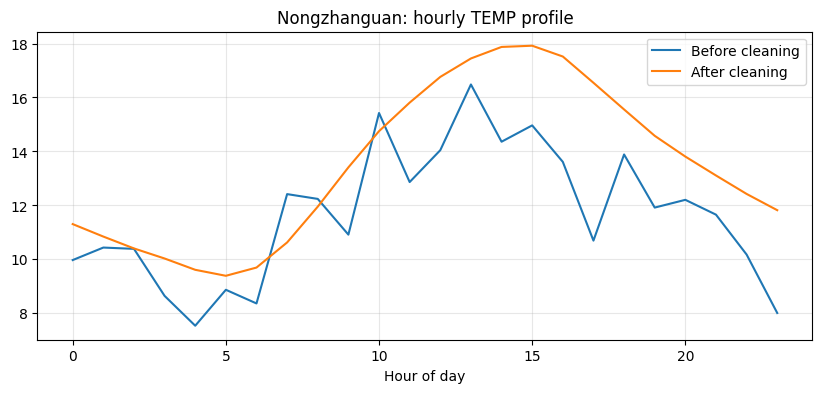

,Before cleaning,After cleaning
hour,,
0,35.078629,41.878202
1,36.496764,38.299302
2,37.840000,34.480971
3,40.696516,30.995229
4,43.963179,27.604488
5,47.134023,26.256951
6,50.282281,24.599794
7,52.023762,23.037758
8,52.792097,24.713708


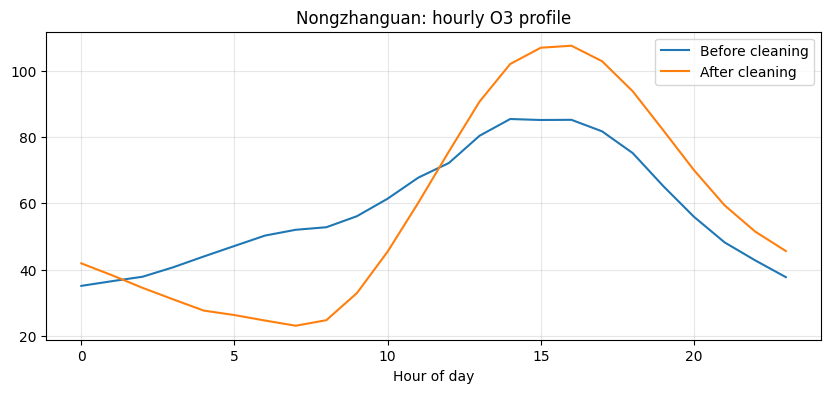

In [ ]:
def hourly_profile(data, station, column):
    subset = data.loc[
        data["station"].eq(station)
        & data[column].notna()
    ]

    return subset.groupby("hour")[column].mean().reindex(range(24))


STATION_TO_CHECK = "Nongzhanguan"

if STATION_TO_CHECK is not None:
    for col in ["TEMP", "O3"]:
        before = hourly_profile(df, STATION_TO_CHECK, col)
        after = hourly_profile(df_clean, STATION_TO_CHECK, col)

        comparison = pd.DataFrame({
            "Before cleaning": before,
            "After cleaning": after
        })

        display(comparison)
        comparison.plot(
            figsize=(10, 4),
            title=f"{STATION_TO_CHECK}: hourly {col} profile"
        )
        plt.xlabel("Hour of day")
        plt.show()

## Task 3 · Imputation study (15 pts)
Using **your cleaned data**, extend A7: compare ≥ 3 imputers (at least one time-aware, e.g. limited interpolation, neighbour-station, seasonal-hourly profile) for **two** pollutants, with both single-hour and 24-h masks. Choose a strategy per gap length and justify it.

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

IMPUTATION_POLLUTANTS = ["PM2.5", "NO2"]

# Work only with the cleaned training data.
imputation_data = (
    df_clean[
        ["station", "datetime", "hour"] + IMPUTATION_POLLUTANTS
    ]
    .copy()
    .sort_values(["station", "datetime"])
    .reset_index(drop=True)
)

print("Data used for the imputation study:")
print(f"Rows: {len(imputation_data):,}")
print(f"Stations: {imputation_data['station'].nunique()}")
print("\nOriginal missingness:")
display(
    imputation_data[IMPUTATION_POLLUTANTS]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .rename("missing_%")
    .to_frame()
)


def create_single_hour_mask(series, random_state=42):
    """
    Mask approximately 10% of observed values as isolated
    single-hour missing values.
    """
    rng = np.random.default_rng(random_state)

    observed_positions = np.flatnonzero(series.notna().to_numpy())

    if len(observed_positions) == 0:
        return np.zeros(len(series), dtype=bool)

    number_to_mask = max(
        1,
        int(len(observed_positions) * 0.10)
    )

    selected = rng.choice(
        observed_positions,
        size=min(number_to_mask, len(observed_positions)),
        replace=False
    )

    mask = np.zeros(len(series), dtype=bool)
    mask[selected] = True

    return mask


def create_24_hour_mask(series, datetime_series, random_state=SEED,number_of_blocks=10):
    """Mask non-overlapping 24-hour windows of observed hourly values."""
    rng = np.random.default_rng(random_state)

    values = series.reset_index(drop=True)
    times = pd.to_datetime(datetime_series).reset_index(drop=True)

    observed = values.notna().to_numpy()
    mask = np.zeros(len(values), dtype=bool)

    candidates = []

    for start in range(len(values) - 23):
        end = start + 24

        # All 24 observations must exist and be non-missing.
        if not observed[start:end].all():
            continue

        # Verify that this is a true 24-hour interval.
        if not times.iloc[start:end].diff().dropna().eq(
            pd.Timedelta(hours=1)
        ).all():
            continue

        candidates.append(start)

    rng.shuffle(candidates)
    selected = []

    for start in candidates:
        end = start + 24

        if mask[start:end].any():
            continue

        mask[start:end] = True
        selected.append(start)

        if len(selected) >= number_of_blocks:
            break

    return mask

def station_median_imputer(masked_series):
    """
    Fill missing values with the median of the same station.
    """
    result = masked_series.copy()
    station_median = masked_series.median()

    return result.fillna(station_median)


def time_interpolation_imputer(
    masked_series,
    datetime_index,
    max_gap_hours=3
):
    """
    Interpolate only short gaps of up to max_gap_hours.
    Leave long gaps and edge gaps missing for a separate fallback.
    """
    original_index = masked_series.index

    s = pd.Series(
        masked_series.to_numpy(dtype=float),
        index=pd.DatetimeIndex(pd.to_datetime(datetime_index))
    ).sort_index()

    # Interpolate only internal gaps. Limit both bounds of the gap,
    # so long gaps are not completely filled.
    filled = s.interpolate(
        method="time",
        limit=max_gap_hours,
        limit_area="inside"
    )

    # Restore original row order and index.
    result = pd.Series(
        filled.reindex(pd.DatetimeIndex(pd.to_datetime(datetime_index))).to_numpy(),
        index=original_index
    )

    return result


def hourly_profile_imputer(masked_series, hour_series):
    """
    Fill from the same station's hour-of-day median.
    Unresolved hours fall back to the median of the visible values.
    """
    values = masked_series.reset_index(drop=True).astype(float)
    hours = hour_series.reset_index(drop=True)

    profile = values.groupby(hours).median()
    result = values.copy()

    missing = result.isna()
    result.loc[missing] = hours.loc[missing].map(profile)

    # Fallback uses only values still visible after masking.
    result = result.fillna(values.median())

    return pd.Series(result.to_numpy(), index=masked_series.index)

def evaluate_one_series(
    original_series,
    datetime_series,
    hour_series,
    gap_type,
    random_state
):
    """
    Artificially hide known values, apply each imputer, and
    compare predictions with the original known values.
    """
    original_series = (
        original_series
        .reset_index(drop=True)
        .astype(float)
    )

    datetime_series = (
        datetime_series
        .reset_index(drop=True)
    )

    hour_series = (
        hour_series
        .reset_index(drop=True)
    )

    mask = None

    for attempt in range(10):
        candidate_mask = (
            create_single_hour_mask(
                original_series,
                random_state=random_state + attempt
            )
            if gap_type == "single hours"
            else create_24_hour_mask(
                original_series,
                datetime_series,
                random_state=random_state + attempt
            )
        )

        if candidate_mask.sum() > 0:
            mask = candidate_mask
            break

    if mask is None or mask.sum() == 0:
        return []

    masked_series = original_series.mask(mask)
    truth = original_series.loc[mask]

    imputers = {
        "station median": station_median_imputer(
            masked_series
        ),

        "time interpolation": time_interpolation_imputer(
            masked_series,
            datetime_series
        ),

        "hour-of-day profile": hourly_profile_imputer(
            masked_series,
            hour_series
        ),
    }

    records = []

    for method_name, imputed_series in imputers.items():
        predictions = imputed_series.loc[mask]

        valid = (
            truth.notna()
            & predictions.notna()
        )

        if valid.sum() == 0:
            continue

        records.append({
            "gap_type": gap_type,
            "method": method_name,
            "masked_values": int(valid.sum()),
            "RMSE": np.sqrt(
                mean_squared_error(
                    truth.loc[valid],
                    predictions.loc[valid]
                )
            ),
            "MAE": mean_absolute_error(
                truth.loc[valid],
                predictions.loc[valid]
            ),
        })

    return records


imputation_results = []

for pollutant in IMPUTATION_POLLUTANTS:

    for station in sorted(
        imputation_data["station"].dropna().unique()
    ):

        station_data = (
            imputation_data[
                imputation_data["station"] == station
            ]
            .sort_values("datetime")
            .reset_index(drop=True)
        )

        for gap_type in [
            "single hours",
            "24-hour blocks"
        ]:

            records = evaluate_one_series(
                original_series=station_data[pollutant],
                datetime_series=station_data["datetime"],
                hour_series=station_data["hour"],
                gap_type=gap_type,
                random_state=1000 + len(imputation_results)
            )

            for record in records:
                record["pollutant"] = pollutant
                record["station"] = station
                imputation_results.append(record)


imputation_results = pd.DataFrame(imputation_results)

print("\nDetailed imputation results:")
display(
    imputation_results
    .sort_values(
        ["pollutant", "gap_type", "RMSE"]
    )
    .round(3)
)

imputation_summary = (
    imputation_results
    .groupby(
        ["pollutant", "gap_type", "method"]
    )
    .agg(
        stations_evaluated=("station", "nunique"),
        masked_values=("masked_values", "sum"),
        mean_RMSE=("RMSE", "mean"),
        mean_MAE=("MAE", "mean")
    )
    .reset_index()
    .sort_values(
        ["pollutant", "gap_type", "mean_RMSE"]
    )
)

print("\nImputation summary:")
display(imputation_summary.round(3))

Data used for the imputation study:
Rows: 315,640
Stations: 12

Original missingness:


,missing_%
PM2.5,2.29
NO2,5.92



Detailed imputation results:


,gap_type,method,masked_values,RMSE,MAE,pollutant,station
112,24-hour blocks,time interpolation,29,7.045,5.383,NO2,Huairou
88,24-hour blocks,time interpolation,30,8.423,5.823,NO2,Dingling
124,24-hour blocks,time interpolation,29,9.471,6.874,NO2,Shunyi
130,24-hour blocks,time interpolation,29,10.521,7.274,NO2,Tiantan
106,24-hour blocks,time interpolation,29,11.782,10.088,NO2,Gucheng
...,...,...,...,...,...,...,...
18,single hours,station median,2575,86.071,58.219,PM2.5,Dongsi
44,single hours,hour-of-day profile,2577,87.969,57.868,PM2.5,Nongzhanguan
42,single hours,station median,2577,88.206,57.983,PM2.5,Nongzhanguan
68,single hours,hour-of-day profile,2575,89.231,59.162,PM2.5,Wanshouxigong



Imputation summary:


,pollutant,gap_type,method,stations_evaluated,masked_values,mean_RMSE,mean_MAE
2,NO2,24-hour blocks,time interpolation,12,351,13.053,9.371
0,NO2,24-hour blocks,hour-of-day profile,12,2880,31.401,23.667
1,NO2,24-hour blocks,station median,12,2880,32.439,25.343
5,NO2,single hours,time interpolation,12,29579,7.779,5.027
3,NO2,single hours,hour-of-day profile,12,29690,32.950,24.479
4,NO2,single hours,station median,12,29690,33.640,25.737
8,PM2.5,24-hour blocks,time interpolation,12,360,29.454,17.842
6,PM2.5,24-hour blocks,hour-of-day profile,12,2880,88.341,61.521
7,PM2.5,24-hour blocks,station median,12,2880,88.663,61.870
11,PM2.5,single hours,time interpolation,12,30757,14.507,7.619


In [ ]:
# TASK 3 — METHOD SELECTION AND GAP-LENGTH POLICY

best_methods = (
    imputation_summary
    .sort_values(
        ["pollutant", "gap_type", "mean_RMSE"]
    )
    .groupby(
        ["pollutant", "gap_type"],
        as_index=False
    )
    .first()
)

print("Best method for each pollutant and gap type:")
display(best_methods.round(3))

print("\nRecommended imputation policy:")

for pollutant in IMPUTATION_POLLUTANTS:

    single_result = best_methods[
        (best_methods["pollutant"] == pollutant)
        & (best_methods["gap_type"] == "single hours")
    ]

    block_result = best_methods[
        (best_methods["pollutant"] == pollutant)
        & (best_methods["gap_type"] == "24-hour blocks")
    ]

    if len(single_result) > 0:
        single_method = single_result.iloc[0]["method"]
        single_rmse = single_result.iloc[0]["mean_RMSE"]

        print(
            f"- {pollutant}, short gaps: "
            f"use {single_method} "
            f"(mean RMSE = {single_rmse:.3f})"
        )

    if len(block_result) > 0:
        block_method = block_result.iloc[0]["method"]
        block_rmse = block_result.iloc[0]["mean_RMSE"]

        print(
            f"- {pollutant}, 24-hour gaps: "
            f"use {block_method} "
            f"(mean RMSE = {block_rmse:.3f})"
        )



Best method for each pollutant and gap type:


,pollutant,gap_type,method,stations_evaluated,masked_values,mean_RMSE,mean_MAE
0,NO2,24-hour blocks,time interpolation,12,351,13.053,9.371
1,NO2,single hours,time interpolation,12,29579,7.779,5.027
2,PM2.5,24-hour blocks,time interpolation,12,360,29.454,17.842
3,PM2.5,single hours,time interpolation,12,30757,14.507,7.619



Recommended imputation policy:
- PM2.5, short gaps: use time interpolation (mean RMSE = 14.507)
- PM2.5, 24-hour gaps: use time interpolation (mean RMSE = 29.454)
- NO2, short gaps: use time interpolation (mean RMSE = 7.779)
- NO2, 24-hour gaps: use time interpolation (mean RMSE = 13.053)


In [ ]:
REPEAT_SEEDS = [SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4]

imputation_results = []

for pollutant in IMPUTATION_POLLUTANTS:
    for station in sorted(
        imputation_data["station"].dropna().unique()
    ):
        station_data = (
            imputation_data.loc[
                imputation_data["station"].eq(station)
            ]
            .sort_values("datetime")
            .reset_index(drop=True)
        )

        for gap_type in ["single hours", "24-hour blocks"]:
            for seed in REPEAT_SEEDS:
                records = evaluate_one_series(
                    original_series=station_data[pollutant],
                    datetime_series=station_data["datetime"],
                    hour_series=station_data["hour"],
                    gap_type=gap_type,
                    random_state=seed
                )

                for record in records:
                    record["pollutant"] = pollutant
                    record["station"] = station
                    record["seed"] = seed
                    imputation_results.append(record)

imputation_results = pd.DataFrame(imputation_results)

display(imputation_results.head())

,gap_type,method,masked_values,RMSE,MAE,pollutant,station,seed
0,single hours,station median,2552,83.078911,56.115439,PM2.5,Aotizhongxin,2135
1,single hours,time interpolation,2545,15.073059,7.156495,PM2.5,Aotizhongxin,2135
2,single hours,hour-of-day profile,2552,83.208647,56.241614,PM2.5,Aotizhongxin,2135
3,single hours,station median,2552,83.646731,55.567633,PM2.5,Aotizhongxin,2136
4,single hours,time interpolation,2543,15.473690,7.452274,PM2.5,Aotizhongxin,2136


In [ ]:
imputation_summary = (
    imputation_results
    .groupby(["pollutant", "gap_type", "method"])
    .agg(
        mean_RMSE=("RMSE", "mean"),
        sd_RMSE=("RMSE", "std"),
        mean_MAE=("MAE", "mean"),
        sd_MAE=("MAE", "std"),
        evaluated_values=("masked_values", "sum"),
        experiments=("seed", "nunique")
    )
    .reset_index()
    .sort_values(["pollutant", "gap_type", "mean_RMSE"])
)

display(imputation_summary.round(3))

,pollutant,gap_type,method,mean_RMSE,sd_RMSE,mean_MAE,sd_MAE,evaluated_values,experiments
2,NO2,24-hour blocks,time interpolation,16.792,5.829,11.856,3.570,1779,5
0,NO2,24-hour blocks,hour-of-day profile,30.137,7.454,22.902,5.299,14400,5
1,NO2,24-hour blocks,station median,31.034,7.233,24.277,5.430,14400,5
5,NO2,single hours,time interpolation,7.810,1.057,5.037,0.706,147742,5
3,NO2,single hours,hour-of-day profile,32.743,3.790,24.332,3.353,148450,5
4,NO2,single hours,station median,33.500,4.008,25.613,3.861,148450,5
8,PM2.5,24-hour blocks,time interpolation,25.334,12.552,16.140,6.733,1788,5
6,PM2.5,24-hour blocks,hour-of-day profile,74.612,24.445,52.301,13.627,14400,5
7,PM2.5,24-hour blocks,station median,74.810,24.477,52.596,13.647,14400,5
11,PM2.5,single hours,time interpolation,14.466,1.682,7.611,0.532,153700,5


## Task 4 · Outliers & transformations (10 pts)
Classify flagged points as **error** (stuck, impossible, code) vs **real episode** (e.g. Spring Festival fireworks, winter smog). Show at least one example of each on a time plot. Report skewness before/after your transform.

In [ ]:
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

outlier_rows = []

for col in pollutants:
    x = pd.to_numeric(df_clean[col], errors="coerce").dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flags = (x < lower) | (x > upper)

    outlier_rows.append({
        "Pollutant": col,
        "Valid observations": len(x),
        "Lower fence": lower,
        "Upper fence": upper,
        "Outlier count": int(flags.sum()),
        "Outlier %": 100 * flags.mean()
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index("Pollutant")
display(outlier_summary.round(3))

,Valid observations,Lower fence,Upper fence,Outlier count,Outlier %
Pollutant,,,,,
PM2.5,308401,-115.0,245.0,13944,4.521
PM10,311021,-130.0,318.0,9740,3.132
SO2,308653,-25.5,50.5,27620,8.949
NO2,296957,-48.0,144.0,4931,1.661
CO,297534,-1150.0,3250.0,17535,5.893
O3,305463,-95.5,188.5,12296,4.025


In [ ]:
from scipy.stats import zscore

x = pd.to_numeric(df_clean["PM2.5"], errors="coerce").dropna()

z_values = pd.Series(
    zscore(x, nan_policy="omit"),
    index=x.index
)

z_flags = z_values.abs() > 3

print("PM2.5 standard Z-score outliers:", int(z_flags.sum()))
print("Threshold: |Z-score| > 3")

PM2.5 standard Z-score outliers: 5215
Threshold: |Z-score| > 3


In [ ]:
x = pd.to_numeric(df_clean["PM2.5"], errors="coerce").dropna()

median = x.median()
mad = (x - median).abs().median()

if mad == 0:
    modified_z = pd.Series(np.nan, index=x.index)
    modified_z_flags = pd.Series(False, index=x.index)
    print("MAD is zero; modified Z-score cannot reliably flag observations.")
else:
    modified_z = 0.6745 * (x - median) / mad
    modified_z_flags = modified_z.abs() > 3.5

print("PM2.5 modified Z-score outliers:", int(modified_z_flags.sum()))
print("Threshold: |modified Z-score| > 3.5")

PM2.5 modified Z-score outliers: 11037
Threshold: |modified Z-score| > 3.5


In [ ]:
x = pd.to_numeric(df_clean["PM2.5"], errors="coerce").dropna()

q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

tukey_flags = (x < lower_fence) | (x > upper_fence)

print("PM2.5 Tukey-fence outliers:", int(tukey_flags.sum()))
print(f"Lower fence: {lower_fence:.3f}")
print(f"Upper fence: {upper_fence:.3f}")

PM2.5 Tukey-fence outliers: 13944
Lower fence: -115.000
Upper fence: 245.000


In [ ]:
from scipy.stats import chi2

mahal_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

mah_data = (
    df_clean[mahal_cols]
    .apply(pd.to_numeric, errors="coerce")
    .dropna()
)

if len(mah_data) <= len(mahal_cols):
    raise ValueError(
        "Not enough complete observations for Mahalanobis-distance analysis."
    )

X = mah_data.to_numpy(dtype=float)

mu = X.mean(axis=0)
cov = np.cov(X, rowvar=False)
cov_inv = np.linalg.pinv(cov)

diff = X - mu

mahal_d2 = np.einsum(
    "ij,jk,ik->i",
    diff,
    cov_inv,
    diff
)

threshold = chi2.ppf(0.999, df=len(mahal_cols))

mahal_flags = pd.Series(
    mahal_d2 > threshold,
    index=mah_data.index,
    name="Mahalanobis outlier"
)

print("Complete observations tested:", len(mah_data))
print("Mahalanobis outliers:", int(mahal_flags.sum()))
print(f"Chi-square threshold (99.9%): {threshold:.3f}")

Complete observations tested: 275661
Mahalanobis outliers: 10557
Chi-square threshold (99.9%): 22.458


In [ ]:
raw = df.copy()

raw["datetime"] = pd.to_datetime(
    raw[["year", "month", "day", "hour"]],
    errors="coerce"
)

raw["PM2.5"] = pd.to_numeric(raw["PM2.5"], errors="coerce")

raw = raw.sort_values(
    ["station", "datetime"]
).reset_index(drop=True)

# Previous reading and timestamp, separately for each station.
grouped = raw.groupby("station", sort=False)

previous_pm25 = grouped["PM2.5"].shift()
previous_time = grouped["datetime"].shift()

same_value = (
    raw["PM2.5"].notna()
    & previous_pm25.notna()
    & raw["PM2.5"].eq(previous_pm25)
)

consecutive_hour = (
    raw["datetime"].notna()
    & previous_time.notna()
    & (raw["datetime"] - previous_time == pd.Timedelta(hours=1))
)

# Start a new run whenever the value changes, a reading is missing,
# or timestamps are not exactly one hour apart.
continues_run = same_value & consecutive_hour

raw["run_id"] = (
    (~continues_run)
    .groupby(raw["station"], sort=False)
    .cumsum()
)

raw["run_length"] = (
    raw.groupby(["station", "run_id"], sort=False)["PM2.5"]
    .transform("size")
)

# Only count non-missing, repeated observations in a run of >= 11 hours.
stuck_candidates = raw.loc[
    raw["PM2.5"].notna()
    & raw["run_length"].ge(11)
    & continues_run
].copy()

run_summary = (
    raw.loc[
        raw["PM2.5"].notna()
        & raw["run_length"].ge(11)
    ]
    .groupby(["station", "run_id"], as_index=False)
    .agg(
        start=("datetime", "min"),
        end=("datetime", "max"),
        run_length=("PM2.5", "size"),
        PM2_5_value=("PM2.5", "first"),
        distinct_values=("PM2.5", "nunique")
    )
)

run_summary["duration"] = run_summary["end"] - run_summary["start"]

run_summary = run_summary.sort_values(
    ["run_length", "station"],
    ascending=[False, True]
).reset_index(drop=True)

print("Detected candidate runs (at least 11 hourly readings):", len(run_summary))
display(run_summary.head(15))

Detected candidate runs (at least 11 hourly readings): 21


,station,run_id,start,end,run_length,PM2_5_value,distinct_values,duration
0,Dongsi,11870,2014-10-11 21:00:00,2014-10-13 11:00:00,39,3.0,1,1 days 14:00:00
1,Huairou,16817,2015-06-25 07:00:00,2015-06-26 06:00:00,24,128.0,1,0 days 23:00:00
2,Huairou,21085,2016-01-27 15:00:00,2016-01-28 14:00:00,24,15.0,1,0 days 23:00:00
3,Huairou,12593,2014-11-27 15:00:00,2014-11-28 12:00:00,22,200.0,1,0 days 21:00:00
4,Huairou,2395,2013-07-01 23:00:00,2013-07-02 19:00:00,21,3.0,1,0 days 20:00:00
5,Huairou,19129,2015-10-20 15:00:00,2015-10-21 11:00:00,21,53.0,1,0 days 20:00:00
6,Huairou,19946,2015-12-01 21:00:00,2015-12-02 17:00:00,21,345.0,1,0 days 20:00:00
7,Dongsi,12319,2014-11-05 21:00:00,2014-11-06 15:00:00,19,3.0,1,0 days 18:00:00
8,Huairou,5311,2013-11-30 14:00:00,2013-12-01 07:00:00,18,52.0,1,0 days 17:00:00
9,Huairou,17543,2015-07-31 17:00:00,2015-08-01 09:00:00,17,22.0,1,0 days 16:00:00


In [ ]:
if run_summary.empty:
    print("No repeated-reading runs of 11 or more hours were detected.")
else:
    display(run_summary.head(10))

,station,run_id,start,end,run_length,PM2_5_value,distinct_values,duration
0,Dongsi,11870,2014-10-11 21:00:00,2014-10-13 11:00:00,39,3.0,1,1 days 14:00:00
1,Huairou,16817,2015-06-25 07:00:00,2015-06-26 06:00:00,24,128.0,1,0 days 23:00:00
2,Huairou,21085,2016-01-27 15:00:00,2016-01-28 14:00:00,24,15.0,1,0 days 23:00:00
3,Huairou,12593,2014-11-27 15:00:00,2014-11-28 12:00:00,22,200.0,1,0 days 21:00:00
4,Huairou,2395,2013-07-01 23:00:00,2013-07-02 19:00:00,21,3.0,1,0 days 20:00:00
5,Huairou,19129,2015-10-20 15:00:00,2015-10-21 11:00:00,21,53.0,1,0 days 20:00:00
6,Huairou,19946,2015-12-01 21:00:00,2015-12-02 17:00:00,21,345.0,1,0 days 20:00:00
7,Dongsi,12319,2014-11-05 21:00:00,2014-11-06 15:00:00,19,3.0,1,0 days 18:00:00
8,Huairou,5311,2013-11-30 14:00:00,2013-12-01 07:00:00,18,52.0,1,0 days 17:00:00
9,Huairou,17543,2015-07-31 17:00:00,2015-08-01 09:00:00,17,22.0,1,0 days 16:00:00


In [ ]:
if run_summary.empty:
    selected_run = None
    run = pd.DataFrame()
    print("No candidate run is available to inspect.")
else:
    selected_run = run_summary.iloc[0]

    run = raw.loc[
        (raw["station"] == selected_run["station"])
        & (raw["datetime"] >= selected_run["start"])
        & (raw["datetime"] <= selected_run["end"])
    ].sort_values("datetime").copy()

    print("Selected station:", selected_run["station"])
    print("Run start:", selected_run["start"])
    print("Run end:", selected_run["end"])
    print("Run length:", selected_run["run_length"], "hours")
    print("Repeated PM2.5 value:", selected_run["PM2_5_value"])

Selected station: Dongsi
Run start: 2014-10-11 21:00:00
Run end: 2014-10-13 11:00:00
Run length: 39 hours
Repeated PM2.5 value: 3.0


In [ ]:
print(df.columns.tolist())

['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station', 'station_canon', 'datetime']


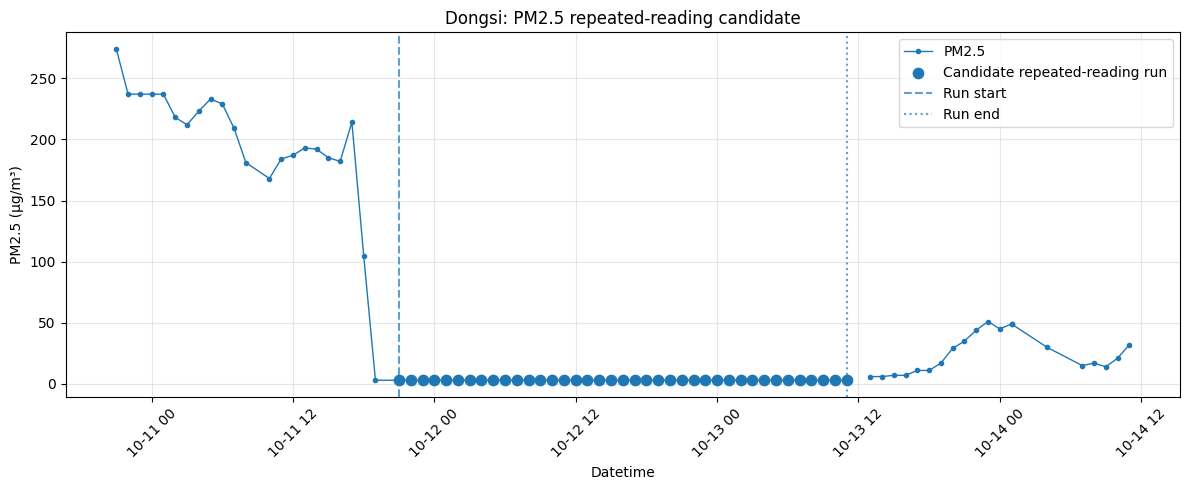

In [ ]:
if run.empty:
    print("Skipping plot because no candidate run was detected.")
else:
    station_name = selected_run["station"]
    start_time = selected_run["start"]
    end_time = selected_run["end"]

    window = raw.loc[
        (raw["station"] == station_name)
        & raw["datetime"].between(
            start_time - pd.Timedelta(hours=24),
            end_time + pd.Timedelta(hours=24)
        )
    ].sort_values("datetime")

    plt.figure(figsize=(12, 5))

    plt.plot(
        window["datetime"],
        window["PM2.5"],
        marker="o",
        markersize=3,
        linewidth=1,
        label="PM2.5"
    )

    plt.scatter(
        run["datetime"],
        run["PM2.5"],
        s=55,
        label="Candidate repeated-reading run",
        zorder=3
    )

    plt.axvline(start_time, linestyle="--", alpha=0.7, label="Run start")
    plt.axvline(end_time, linestyle=":", alpha=0.7, label="Run end")

    plt.xlabel("Datetime")
    plt.ylabel("PM2.5 (µg/m³)")
    plt.title(f"{station_name}: PM2.5 repeated-reading candidate")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
if run.empty:
    print("No run to display.")
else:
    available_cols = [
        col for col in ["datetime", "PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
        if col in run.columns
    ]

    display(run[available_cols])

,datetime,PM2.5,PM10,SO2,NO2,CO,O3
90218,2014-10-11 21:00:00,3.0,3.0,5.0,28.0,400.0,44.0
90219,2014-10-11 22:00:00,3.0,3.0,4.0,25.0,300.0,49.0
90220,2014-10-11 23:00:00,3.0,3.0,5.0,25.0,300.0,48.0
90221,2014-10-12 00:00:00,3.0,3.0,4.0,23.0,300.0,51.0
90222,2014-10-12 01:00:00,3.0,3.0,3.0,22.0,300.0,50.0
90223,2014-10-12 02:00:00,3.0,3.0,3.0,27.0,300.0,41.0
90224,2014-10-12 03:00:00,3.0,3.0,8.0,26.0,300.0,40.0
90225,2014-10-12 04:00:00,3.0,3.0,10.0,26.0,300.0,38.0
90226,2014-10-12 05:00:00,3.0,3.0,8.0,25.0,300.0,37.0
90227,2014-10-12 06:00:00,3.0,3.0,4.0,24.0,300.0,35.0


In [ ]:
if run.empty:
    print("No run to summarize.")
else:
    print("Station:", selected_run["station"])
    print("Number of observations:", len(run))
    print("Number of unique PM2.5 values:", run["PM2.5"].nunique())
    print("PM2.5 values:", run["PM2.5"].unique())

    if len(run) > 1:
        duration = run["datetime"].max() - run["datetime"].min()
        print("Elapsed duration:", duration)
        print("Elapsed hours:", duration.total_seconds() / 3600)

    other_pollutants = [
        col for col in ["PM10", "SO2", "NO2", "CO", "O3"]
        if col in run.columns
    ]

    if other_pollutants:
        print("\nOther pollutant variability during the run:")
        display(run[other_pollutants].agg(["min", "max", "nunique"]).T)

Station: Dongsi
Number of observations: 39
Number of unique PM2.5 values: 1
PM2.5 values: [3.]
Elapsed duration: 1 days 14:00:00
Elapsed hours: 38.0

Other pollutant variability during the run:


,min,max,nunique
PM10,3.0,28.0,8.0
SO2,2.0,10.0,6.0
NO2,11.0,40.0,17.0
CO,200.0,400.0,3.0
O3,21.0,56.0,25.0


In [ ]:
context_cols = [
    col for col in [
        "station", "datetime", "PM2.5", "PM10", "SO2", "NO2", "CO", "O3"
    ]
    if col in df_clean.columns
]

top = (
    df_clean[context_cols]
    .dropna(subset=["PM2.5", "datetime"])
    .nlargest(20, "PM2.5")
    .sort_values("PM2.5", ascending=False)
    .reset_index(drop=True)
)

display(top)

,station,datetime,PM2.5,PM10,SO2,NO2,CO,O3
0,Wanshouxigong,2016-02-08 02:00:00,999.0,NaN,299.0,82.0,2700.0,6.0
1,Wanliu,2016-02-08 02:00:00,957.0,NaN,282.0,92.0,1600.0,7.0
2,Shunyi,2016-02-08 02:00:00,941.0,NaN,153.0,70.0,2400.0,6.0
3,Aotizhongxin,2016-02-08 02:00:00,898.0,NaN,341.0,92.0,1900.0,10.0
4,Changping,2016-02-08 02:00:00,882.0,NaN,215.0,81.0,2900.0,4.0
5,Dingling,2016-02-08 01:00:00,881.0,NaN,156.0,49.0,1100.0,20.0
6,Wanshouxigong,2016-02-08 03:00:00,857.0,NaN,256.0,82.0,2400.0,6.0
7,Wanshouxigong,2016-02-08 01:00:00,826.0,NaN,411.0,81.0,2400.0,7.0
8,Tiantan,2016-02-08 03:00:00,821.0,988.0,182.0,88.0,1900.0,3.0
9,Shunyi,2016-02-08 01:00:00,816.0,NaN,239.0,75.0,1700.0,5.0


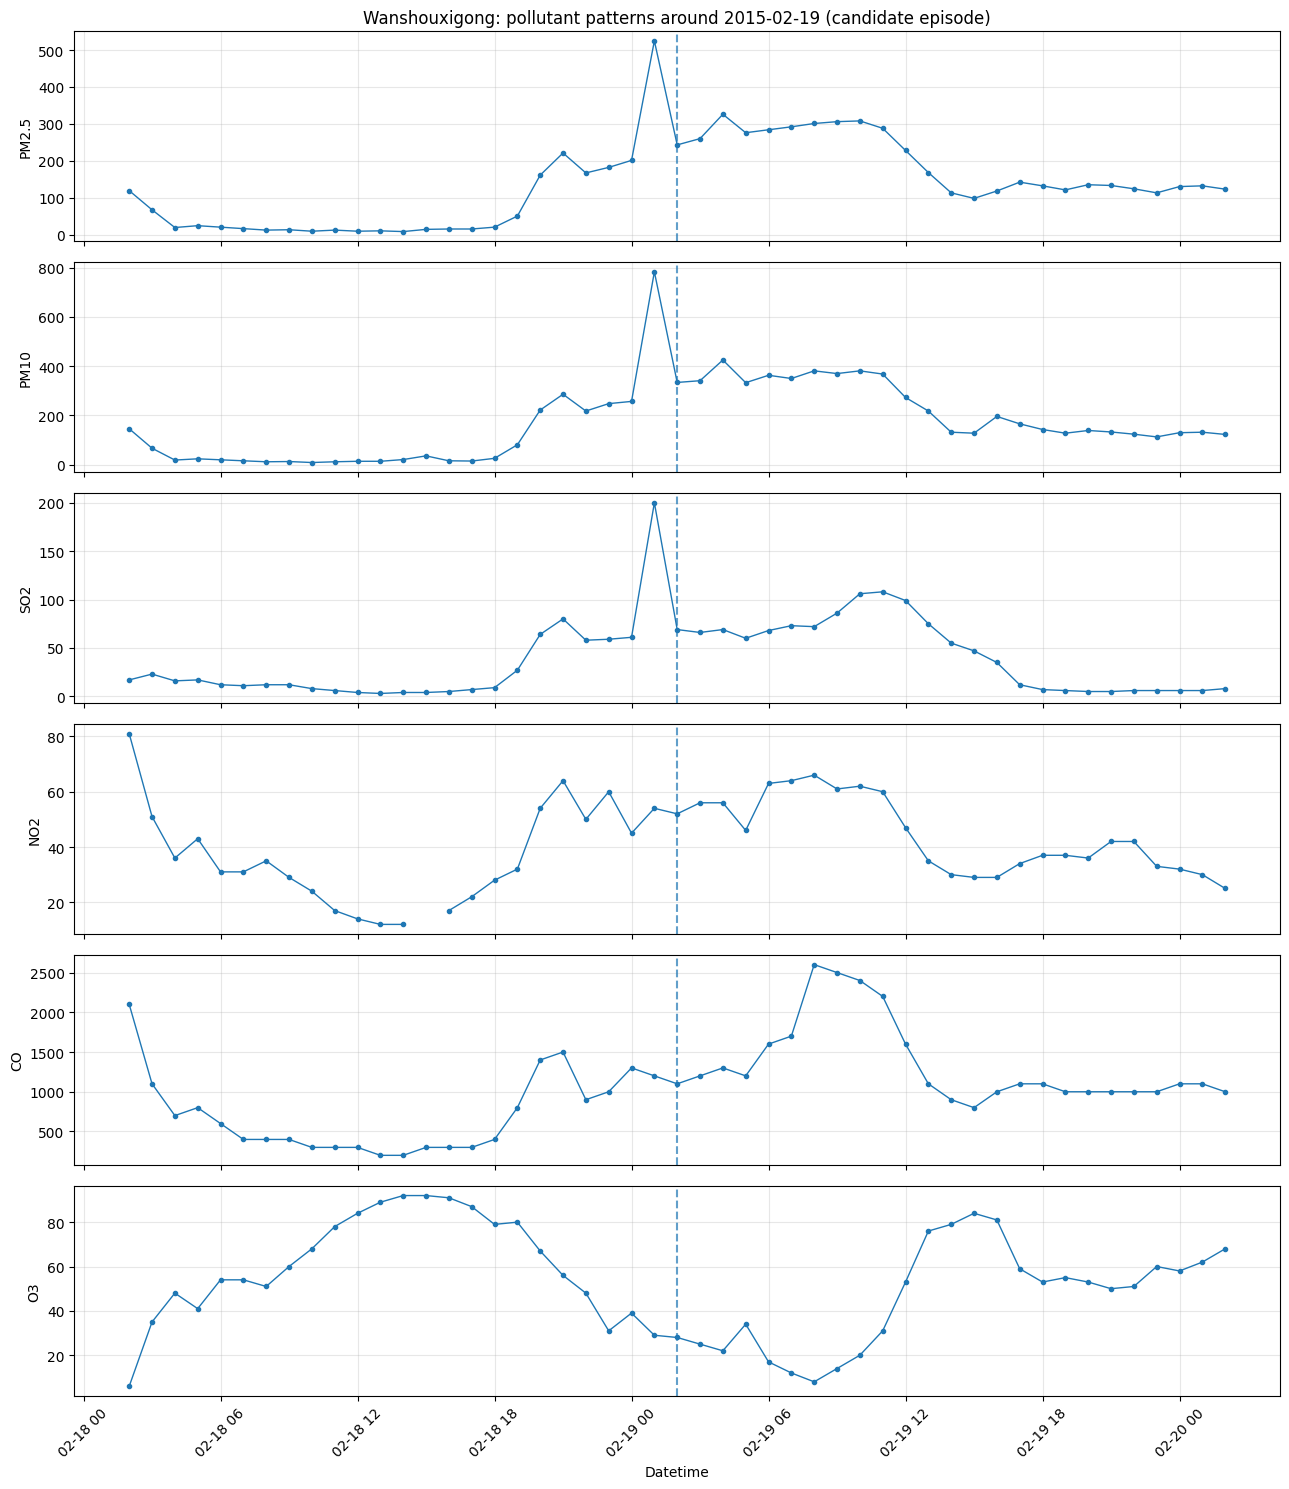

,datetime,PM2.5,PM10,SO2,NO2,CO,O3
306594,2015-02-18 02:00:00,119.0,146.0,17.0,81.0,2100.0,6.0
306595,2015-02-18 03:00:00,67.0,67.0,23.0,51.0,1100.0,35.0
306596,2015-02-18 04:00:00,19.0,19.0,16.0,36.0,700.0,48.0
306597,2015-02-18 05:00:00,24.0,24.0,17.0,43.0,800.0,41.0
306598,2015-02-18 06:00:00,20.0,20.0,12.0,31.0,600.0,54.0
306599,2015-02-18 07:00:00,16.0,16.0,11.0,31.0,400.0,54.0
306600,2015-02-18 08:00:00,12.0,12.0,12.0,35.0,400.0,51.0
306601,2015-02-18 09:00:00,13.0,13.0,12.0,29.0,400.0,60.0
306602,2015-02-18 10:00:00,9.0,9.0,8.0,24.0,300.0,68.0
306603,2015-02-18 11:00:00,12.0,12.0,6.0,17.0,300.0,78.0


In [ ]:
station = "Wanshouxigong"
event_time = pd.Timestamp("2015-02-19 02:00:00")

episode_cols = [
    col for col in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
    if col in df_clean.columns
]

example = df_clean.loc[
    (df_clean["station"] == station)
    & df_clean["datetime"].between(
        event_time - pd.Timedelta(hours=24),
        event_time + pd.Timedelta(hours=24)
    )
].sort_values("datetime").copy()

if example.empty:
    print(
        f"No observations found for {station} around {event_time}. "
        "Choose a training-period high-PM2.5 event from Cell 104 instead."
    )
else:
    fig, axes = plt.subplots(
        len(episode_cols), 1,
        figsize=(13, 2.5 * len(episode_cols)),
        sharex=True
    )

    if len(episode_cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, episode_cols):
        ax.plot(example["datetime"], example[col], marker=".", linewidth=1)
        ax.axvline(event_time, linestyle="--", alpha=0.7)
        ax.set_ylabel(col)

    axes[0].set_title(
        f"{station}: pollutant patterns around {event_time:%Y-%m-%d} "
        "(candidate episode)"
    )
    axes[-1].set_xlabel("Datetime")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    display(example[["datetime"] + episode_cols].head(10))

In [ ]:
transform_cols = ["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]
transform_cols = [col for col in transform_cols if col in df_clean.columns]

transform_data = df_clean[transform_cols].apply(
    pd.to_numeric, errors="coerce"
)

invalid_for_log = {
    col: int((transform_data[col].dropna() < 0).sum())
    for col in transform_cols
}

print("Negative values excluded from log1p by column:", invalid_for_log)

skew_rows = []

for col in transform_cols:
    x = transform_data[col].dropna()
    x = x[x >= 0]

    if len(x) < 3:
        skew_rows.append({
            "Variable": col,
            "Valid nonnegative values": len(x),
            "Raw skewness": np.nan,
            "log1p skewness": np.nan,
            "Absolute skew reduction": np.nan
        })
        continue

    raw_skew_value = x.skew()
    log_skew_value = np.log1p(x).skew()

    skew_rows.append({
        "Variable": col,
        "Valid nonnegative values": len(x),
        "Raw skewness": raw_skew_value,
        "log1p skewness": log_skew_value,
        "Absolute skew reduction": (
            abs(raw_skew_value) - abs(log_skew_value)
        )
    })

skewness_table = pd.DataFrame(skew_rows).set_index("Variable")

display(skewness_table.round(3))

Negative values excluded from log1p by column: {'PM2.5': 0, 'SO2': 0, 'CO': 0, 'NO2': 0, 'O3': 0, 'WSPM': 0}


,Valid nonnegative values,Raw skewness,log1p skewness,Absolute skew reduction
Variable,,,,
PM2.5,308401,1.983,-0.327,1.657
SO2,308653,2.768,0.412,2.356
CO,297534,2.437,-0.010,2.427
NO2,296957,1.015,-0.727,0.289
O3,305463,1.738,-0.593,1.144
WSPM,315462,1.668,0.293,1.376


## Task 5 · Leak-free pipeline + TimeSeriesSplit CV (15 pts)
Use `add_features` and adapt `make_pipeline` (A10). Report 5-fold `TimeSeriesSplit` RMSE ± sd for the virtual sensor on `df_clean` (sorted by `datetime`). Try at least two preprocessing variants (e.g. with/without missing indicators, log-target via `TransformedTargetRegressor`).

In [ ]:
TARGET = "PM2.5"

assert "PM10" not in NUM_FEATS
assert TARGET not in NUM_FEATS
assert TARGET not in CAT_FEATS

print("Target:", TARGET)
print("Numerical predictors:", NUM_FEATS)
print("Categorical predictors:", CAT_FEATS)

Target: PM2.5
Numerical predictors: ['SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'TD_dep', 'rain_flag', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow', 'wd_sin', 'wd_cos']
Categorical predictors: ['station']


In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Build the cleaned training data. Do not use test_year here.
data5 = (
    add_features(df_clean.drop(columns=["datetime"], errors="ignore"))
    .dropna(subset=[TARGET])
    .sort_values("datetime")
    .reset_index(drop=True)
)

X5 = data5[NUM_FEATS + CAT_FEATS]
y5 = data5[TARGET]

# Split the unique timestamps, not individual station rows.
unique_times = np.sort(data5["datetime"].dropna().unique())
tscv = TimeSeriesSplit(n_splits=5)

cv_splits = []

for train_time_idx, valid_time_idx in tscv.split(unique_times):
    train_end = unique_times[train_time_idx[-1]]
    valid_start = unique_times[valid_time_idx[0]]
    valid_end = unique_times[valid_time_idx[-1]]

    train_idx = np.flatnonzero(
        data5["datetime"].to_numpy() <= train_end
    )

    valid_idx = np.flatnonzero(
        (data5["datetime"].to_numpy() >= valid_start)
        & (data5["datetime"].to_numpy() <= valid_end)
    )

    assert data5.loc[train_idx, "datetime"].max() < (
        data5.loc[valid_idx, "datetime"].min()
    ), "Temporal overlap between training and validation."

    cv_splits.append((train_idx, valid_idx))

print("CV folds:", len(cv_splits))
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    print(
        f"Fold {fold}: "
        f"train rows={len(train_idx):,}, "
        f"validation rows={len(valid_idx):,}, "
        f"train end={data5.loc[train_idx, 'datetime'].max()}, "
        f"validation start={data5.loc[valid_idx, 'datetime'].min()}"
    )

CV folds: 5
Fold 1: train rows=51,383, validation rows=51,813, train end=2013-08-30 08:00:00, validation start=2013-08-30 09:00:00
Fold 2: train rows=103,196, validation rows=51,318, train end=2014-03-01 11:00:00, validation start=2014-03-01 12:00:00
Fold 3: train rows=154,514, validation rows=51,020, train end=2014-08-30 19:00:00, validation start=2014-08-30 20:00:00
Fold 4: train rows=205,534, validation rows=51,473, train end=2015-03-01 10:00:00, validation start=2015-03-01 11:00:00
Fold 5: train rows=257,007, validation rows=51,394, train end=2015-08-31 03:00:00, validation start=2015-08-31 04:00:00


In [ ]:
print(make_pipeline)

<function make_pipeline at 0x7d03a2b4cae0>


In [ ]:
print("X5 columns:")
print(X5.columns.tolist())

print("\nNUM_FEATS:")
print(NUM_FEATS)

print("\nCAT_FEATS:")
print(CAT_FEATS)

X5 columns:
['SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'TD_dep', 'rain_flag', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow', 'wd_sin', 'wd_cos', 'station']

NUM_FEATS:
['SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'TD_dep', 'rain_flag', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow', 'wd_sin', 'wd_cos']

CAT_FEATS:
['station']


In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import HistGradientBoostingRegressor

tscv = TimeSeriesSplit(n_splits=5)

# Wrap the model in the pre-defined leak-free make_pipeline function which handles categorical encoding
pipeline_1 = make_pipeline(
    HistGradientBoostingRegressor(
        max_iter=300,
        random_state=0
    )
)

scores_1 = cross_val_score(
    pipeline_1,
    X5,
    y5,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

rmse_1 = -scores_1

print("Fold RMSE:", rmse_1)
print(f"Mean RMSE: {rmse_1.mean():.3f}")
print(f"Std RMSE:  {rmse_1.std():.3f}")

Fold RMSE: [64.42586104 35.3881984  39.77250364 34.21739256 44.83584203]
Mean RMSE: 43.728
Std RMSE:  11.003


In [ ]:
def make_pipeline_no_indicators(model):

    num = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])

    cat = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    prep = ColumnTransformer([
        ("num", num, NUM_FEATS),
        ("cat", cat, CAT_FEATS)
    ], sparse_threshold=0)

    return Pipeline([
        ("prep", prep),
        ("model", model)
    ])

In [ ]:
pipeline_2 = make_pipeline_no_indicators(
    HistGradientBoostingRegressor(
        max_iter=300,
        random_state=0
    )
)

scores_2 = cross_val_score(
    pipeline_2,
    X5,
    y5,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

rmse_2 = -scores_2

print("Fold RMSE:", rmse_2)
print(f"Mean RMSE: {rmse_2.mean():.3f}")
print(f"Std RMSE:  {rmse_2.std():.3f}")

Fold RMSE: [63.13028115 36.14541987 40.58481394 34.94020172 45.15585545]
Mean RMSE: 43.991
Std RMSE:  10.225


In [ ]:
from sklearn.metrics import mean_squared_error

model_template = HistGradientBoostingRegressor(
    max_iter=300,
    random_state=SEED
)

pipeline_with_indicators = make_pipeline(
    clone(model_template)
)

pipeline_without_indicators = make_pipeline_no_indicators(
    clone(model_template)
)

def evaluate_cv_folds(pipeline, X, y, splits):
    rows = []

    for fold, (train_idx, valid_idx) in enumerate(splits, start=1):
        model = clone(pipeline)

        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[valid_idx])

        rmse = np.sqrt(
            mean_squared_error(y.iloc[valid_idx], pred)
        )

        rows.append({
            "fold": fold,
            "RMSE": rmse,
            "train_rows": len(train_idx),
            "validation_rows": len(valid_idx)
        })

    return pd.DataFrame(rows)

cv_with = evaluate_cv_folds(
    pipeline_with_indicators, X5, y5, cv_splits
)
cv_with["variant"] = "With missing indicators"

cv_without = evaluate_cv_folds(
    pipeline_without_indicators, X5, y5, cv_splits
)
cv_without["variant"] = "Without missing indicators"

cv_results = pd.concat(
    [cv_with, cv_without],
    ignore_index=True
)

display(cv_results.round(3))

cv_summary = (
    cv_results.groupby("variant")["RMSE"]
    .agg(["mean", "std"])
    .rename(columns={"mean": "Mean RMSE", "std": "RMSE SD"})
)

display(cv_summary.round(3))

,fold,RMSE,train_rows,validation_rows,variant
0,1,63.599,51383,51813,With missing indicators
1,2,35.200,103196,51318,With missing indicators
2,3,39.494,154514,51020,With missing indicators
3,4,33.991,205534,51473,With missing indicators
4,5,44.573,257007,51394,With missing indicators
5,1,64.568,51383,51813,Without missing indicators
6,2,35.467,103196,51318,Without missing indicators
7,3,40.391,154514,51020,Without missing indicators
8,4,34.520,205534,51473,Without missing indicators
9,5,44.546,257007,51394,Without missing indicators


,Mean RMSE,RMSE SD
variant,,
With missing indicators,43.371,12.046
Without missing indicators,43.899,12.237


## Task 6 · Impact study — does data quality matter? (20 pts)
Train the **same model** two ways and score both on the **same complete-case rows of the test year**:
1. **Naive:** the merged export as-is (features built, rows with missing values dropped, raw labels).
2. **Yours:** `clean_basic` + your imputation + your pipeline.
Report RMSE, MAE, R², a predicted-vs-actual plot and the error by station. Explain the difference.

In [ ]:
# Task 6: verify the untouched temporal holdout.
assert "test_year" in globals()
assert "train_raw" in globals()

assert train_raw["datetime"].max() < SPLIT
assert test_year["datetime"].min() >= SPLIT

print("Training cutoff:", SPLIT)
print("Last training timestamp:", train_raw["datetime"].max())
print("First test timestamp:", test_year["datetime"].min())
print("Training rows:", f"{len(train_raw):,}")
print("Test-year rows:", f"{len(test_year):,}")

Training cutoff: 2016-03-01 00:00:00
Last training timestamp: 2016-02-29 23:00:00
First test timestamp: 2016-03-01 00:00:00
Training rows: 315,648
Test-year rows: 105,120


Common test observations: 97,979
Test period: 2016-03-01 00:00:00 to 2017-02-28 23:00:00
Naive training rows: 311565

Applying Task 5 imputation:
Method: Time interpolation
Cleaned training rows: 308401

TASK 6 — DATA QUALITY IMPACT


,RMSE,MAE,R2
Naive,36.895,22.272,0.799
Cleaned,36.780,21.970,0.801


,Metric,Improvement (%)
0,RMSE,0.31
1,MAE,1.36


R² change: 0.001


,station,observations,Naive_RMSE,Cleaned_RMSE,Naive_MAE,Cleaned_MAE,RMSE_Improvement_%
3,Dongsi,8177,40.081,40.461,24.434,24.494,-0.950
6,Huairou,8073,30.325,30.546,18.666,18.520,-0.729
0,Aotizhongxin,8211,36.753,36.854,22.154,21.922,-0.274
5,Gucheng,8441,38.145,38.125,22.967,22.568,0.052
11,Wanshouxigong,8343,41.477,41.406,24.202,23.596,0.170
7,Nongzhanguan,8299,36.268,36.195,22.172,21.900,0.204
4,Guanyuan,8316,37.836,37.702,23.280,23.148,0.355
10,Wanliu,8297,35.032,34.908,21.107,20.815,0.356
8,Shunyi,7158,39.485,39.320,23.608,23.373,0.417
9,Tiantan,8462,39.010,38.705,23.113,22.714,0.781


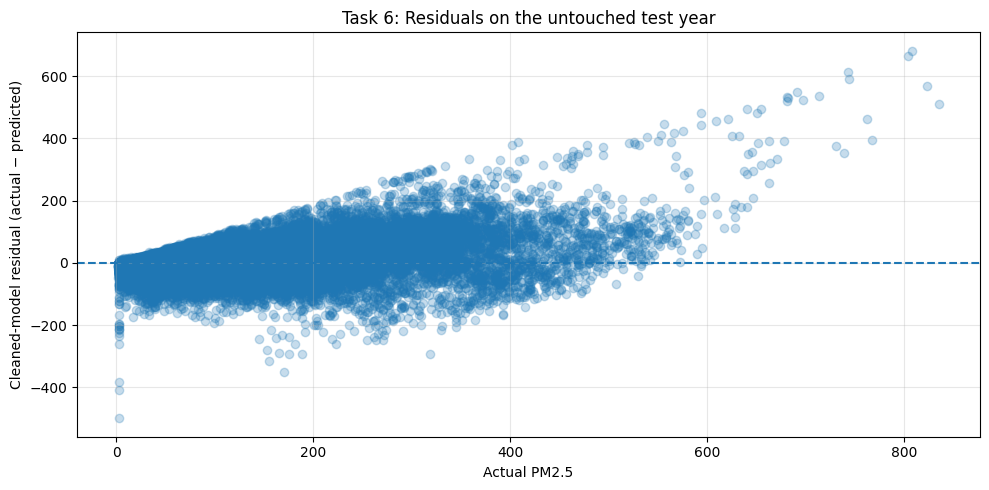

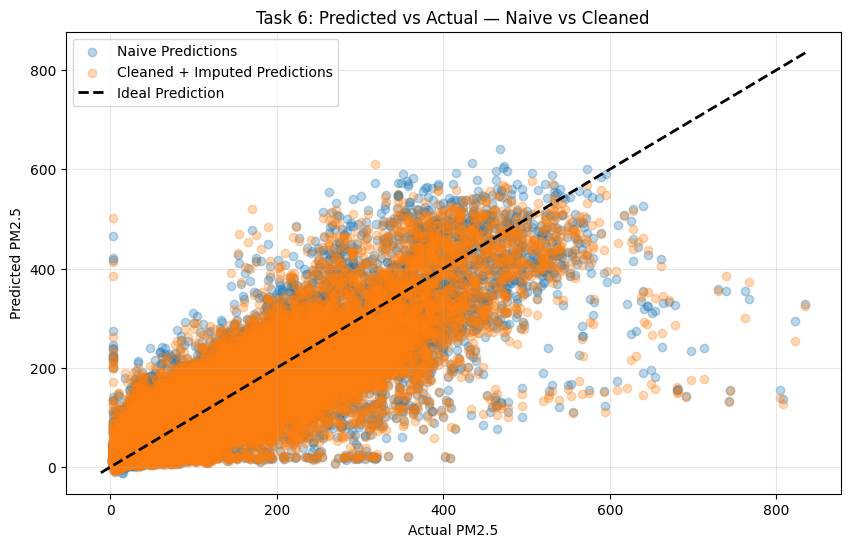


=== MAE BY STATION ===


,Naive_MAE,Cleaned_MAE,Observations
station,,,
Aotizhongxin,22.154,21.922,8211
Changping,23.198,22.659,8406
Dingling,18.178,17.765,7796
Dongsi,24.434,24.494,8177
Guanyuan,23.280,23.148,8316
Gucheng,22.967,22.568,8441
Huairou,18.666,18.520,8073
Nongzhanguan,22.172,21.900,8299
Shunyi,23.608,23.373,7158



=== STATION-LEVEL IMPROVEMENT ===


,Naive_MAE,Cleaned_MAE,Observations,Improvement_%
station,,,,
Wanshouxigong,24.202,23.596,8343,2.50
Changping,23.198,22.659,8406,2.32
Dingling,18.178,17.765,7796,2.27
Gucheng,22.967,22.568,8441,1.74
Tiantan,23.113,22.714,8462,1.73
Wanliu,21.107,20.815,8297,1.38
Nongzhanguan,22.172,21.900,8299,1.23
Aotizhongxin,22.154,21.922,8211,1.05
Shunyi,23.608,23.373,7158,1.00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor


# ============================================================
# 1. Metric Helper
# ============================================================

def scores(y, p):
    return {
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p)
    }


# ============================================================
# 2+3. Model Pipeline + Processor
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor

def get_pipeline():
    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median", add_indicator=True)
        )
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    preprocessor = ColumnTransformer(
          transformers=[
              ("numeric", numeric_pipeline, NUM_FEATS),
              ("categorical", categorical_pipeline, CAT_FEATS)
          ],
          remainder="drop"
      )


    return Pipeline([
        ("preprocessing", preprocessor),
        (
            "model",
            HistGradientBoostingRegressor(
                max_iter=300,
                random_state=SEED
            )
        )
    ])

# ============================================================
# 4. PREPARE THE TEST YEAR
# ============================================================
#
# IMPORTANT:
# We create the same complete-case test rows for BOTH models.
#
# This means both models are evaluated on exactly the same
# observations.
# ============================================================

test_f = (
    add_features(
        test_year.drop(columns=["datetime"], errors="ignore")
    )
    .dropna(subset=NUM_FEATS + CAT_FEATS + [TARGET])
    .reset_index(drop=True)
)

assert "PM10" not in NUM_FEATS
assert TARGET not in NUM_FEATS
assert test_f[NUM_FEATS + CAT_FEATS + [TARGET]].notna().all().all()

print("Common test observations:", f"{len(test_f):,}")
print("Test period:", test_f["datetime"].min(), "to", test_f["datetime"].max())

# ============================================================
# 5. MODEL A — NAIVE BASELINE
# ============================================================
#
# Naive:
#   Original merged export
#       ↓
#   Feature engineering
#       ↓
#   Drop missing rows
#
# No cleaning
# No imputation
# ============================================================

naive_train = (
    add_features(df.drop(columns=["datetime"], errors="ignore"))
    .dropna(subset=[TARGET])
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("Naive training rows:", len(naive_train))

naive_model = get_pipeline()

naive_model.fit(
    naive_train[NUM_FEATS + CAT_FEATS],
    naive_train[TARGET]
)

pred_naive = naive_model.predict(
    test_f[NUM_FEATS + CAT_FEATS]
)

res_naive = scores(
    test_f[TARGET],
    pred_naive
)


# ============================================================
# 6. MODEL B — YOUR CLEANED + IMPUTED PIPELINE
# ============================================================
#
# Your pipeline:
#   clean_basic
#       ↓
#   Time interpolation
#       ↓
#   Feature engineering
#       ↓
#   Drop remaining missing rows
#       ↓
#   Train model
#
# We explicitly use the imputation method from Task 5.
# ============================================================

df_clean = clean_basic(df)


# ------------------------------------------------------------
# Choose the imputation method
# ------------------------------------------------------------
#
# From your Task 5 code:
#
#   station_median_imputer()
#   time_interpolation_imputer()
#   hourly_profile_imputer()
#
# Here we use TIME INTERPOLATION.
# ------------------------------------------------------------

def apply_time_interpolation(df_input):
    """
    Apply time interpolation separately for each station.

    Remaining missing values are filled using the station median.
    """

    result = df_input.copy()

    result = result.sort_values(
        ["station", "datetime"]
    ).reset_index(drop=True)

    for col in NUM_FEATS:

        if col not in result.columns:
            continue

        result[col] = (
            result
            .groupby("station", group_keys=False)
            .apply(
                lambda group: time_interpolation_imputer(
                    group[col],
                    group["datetime"]
                ),
                include_groups=False
            )
            .reset_index(level=0, drop=True)
        )

    return result


print("\nApplying Task 5 imputation:")
print("Method: Time interpolation")


df_clean = apply_time_interpolation(df_clean)


# ============================================================
# 7. BUILD CLEAN TRAINING DATA
# ============================================================

clean_train = (
    add_features(
        df_clean.drop(columns=["datetime"], errors="ignore")
    )
    .dropna(subset=[TARGET])
    .sort_values("datetime")
    .reset_index(drop=True)
)


print("Cleaned training rows:", len(clean_train))


# ============================================================
# 8. TRAIN YOUR MODEL
# ============================================================

clean_model = get_pipeline()

clean_model.fit(
    clean_train[NUM_FEATS + CAT_FEATS],
    clean_train[TARGET]
)

pred_clean = clean_model.predict(
    test_f[NUM_FEATS + CAT_FEATS]
)

res_clean = scores(
    test_f[TARGET],
    pred_clean
)


# ============================================================
# 9. OVERALL METRICS COMPARISON
# ============================================================

print("\n" + "=" * 60)
print("TASK 6 — DATA QUALITY IMPACT")
print("=" * 60)


from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

def calculate_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Naive": calculate_metrics(test_f[TARGET], pred_naive),
    "Cleaned": calculate_metrics(test_f[TARGET], pred_clean)
}).T

display(results.round(3))

# ============================================================
# 10. CALCULATE IMPROVEMENT
# ============================================================

improvement = pd.DataFrame({
    "Metric": ["RMSE", "MAE"],
    "Improvement (%)": [
        100 * (results.loc["Naive", "RMSE"] - results.loc["Cleaned", "RMSE"])
        / results.loc["Naive", "RMSE"],
        100 * (results.loc["Naive", "MAE"] - results.loc["Cleaned", "MAE"])
        / results.loc["Naive", "MAE"]
    ]
})

display(improvement.round(2))

print(
    "R² change:",
    round(results.loc["Cleaned", "R2"] - results.loc["Naive", "R2"], 3)
)


# ============================================================
# 11. PREDICTED VS ACTUAL
# ============================================================

eval_df = test_f[["station", TARGET]].copy()
eval_df["pred_naive"] = pred_naive
eval_df["pred_clean"] = pred_clean

eval_df["residual_naive"] = eval_df[TARGET] - eval_df["pred_naive"]
eval_df["residual_clean"] = eval_df[TARGET] - eval_df["pred_clean"]

station_metrics = []

for station, group in eval_df.groupby("station"):
    station_metrics.append({
        "station": station,
        "observations": len(group),
        "Naive_RMSE": np.sqrt(
            mean_squared_error(group[TARGET], group["pred_naive"])
        ),
        "Cleaned_RMSE": np.sqrt(
            mean_squared_error(group[TARGET], group["pred_clean"])
        ),
        "Naive_MAE": mean_absolute_error(
            group[TARGET], group["pred_naive"]
        ),
        "Cleaned_MAE": mean_absolute_error(
            group[TARGET], group["pred_clean"]
        )
    })

station_metrics = pd.DataFrame(station_metrics)
station_metrics["RMSE_Improvement_%"] = (
    100 * (
        station_metrics["Naive_RMSE"] - station_metrics["Cleaned_RMSE"]
    ) / station_metrics["Naive_RMSE"]
)

display(station_metrics.sort_values("RMSE_Improvement_%").round(3))

plt.figure(figsize=(10, 5))
plt.scatter(
    eval_df[TARGET],
    eval_df["residual_clean"],
    alpha=0.25
)
plt.axhline(0, linestyle="--")
plt.xlabel("Actual PM2.5")
plt.ylabel("Cleaned-model residual (actual − predicted)")
plt.title("Task 6: Residuals on the untouched test year")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

plt.scatter(
    test_f[TARGET],
    pred_naive,
    alpha=0.3,
    label="Naive Predictions"
)

plt.scatter(
    test_f[TARGET],
    pred_clean,
    alpha=0.3,
    label="Cleaned + Imputed Predictions"
)

min_value = min(
    test_f[TARGET].min(),
    pred_naive.min(),
    pred_clean.min()
)

max_value = max(
    test_f[TARGET].max(),
    pred_naive.max(),
    pred_clean.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "k--",
    linewidth=2,
    label="Ideal Prediction"
)

plt.xlabel(f"Actual {TARGET}")
plt.ylabel(f"Predicted {TARGET}")

plt.title(
    "Task 6: Predicted vs Actual — Naive vs Cleaned"
)

plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 12. ERROR BY STATION
# ============================================================

eval_df = test_f[
    ["station", TARGET]
].copy()

eval_df["Predicted_Naive"] = pred_naive
eval_df["Predicted_Cleaned"] = pred_clean

eval_df["Error_Naive"] = (
    eval_df[TARGET] -
    eval_df["Predicted_Naive"]
)

eval_df["Error_Cleaned"] = (
    eval_df[TARGET] -
    eval_df["Predicted_Cleaned"]
)

eval_df["Absolute_Error_Naive"] = (
    eval_df["Error_Naive"].abs()
)

eval_df["Absolute_Error_Cleaned"] = (
    eval_df["Error_Cleaned"].abs()
)


station_mae = (
    eval_df
    .groupby("station")
    .agg(
        Naive_MAE=(
            "Absolute_Error_Naive",
            "mean"
        ),
        Cleaned_MAE=(
            "Absolute_Error_Cleaned",
            "mean"
        ),
        Observations=(
            TARGET,
            "count"
        )
    )
    .round(3)
)

print("\n=== MAE BY STATION ===")

display(station_mae)


# ============================================================
# 13. STATION-LEVEL IMPROVEMENT
# ============================================================

station_mae["Improvement_%"] = (
    (
        station_mae["Naive_MAE"]
        -
        station_mae["Cleaned_MAE"]
    )
    /
    station_mae["Naive_MAE"]
    * 100
).round(2)

print("\n=== STATION-LEVEL IMPROVEMENT ===")

display(
    station_mae.sort_values(
        "Improvement_%",
        ascending=False
    )
)

## ★ HPC bonus (+10 pts) — parallel per-station cleaning
The 12 stations are independent: run `clean_basic` + your imputation **per station** with `joblib.Parallel` (or Dask) and compare wall-time for 1, 2, 4 … workers. Report the speed-up $S_p=T_1/T_p$, efficiency $E_p=S_p/p$ and the dominant step.

In [ ]:
import time
import numpy as np
import pandas as pd

from joblib import Parallel, delayed


# ============================================================
# 1. Clean + Impute One Station
# ============================================================

def clean_one_station(g):
    """
    Clean and impute data for one monitoring station.

    Pipeline:
        clean_basic
            ↓
        time interpolation
            ↓
        station median fallback
    """

    # Make a copy so the original data is not modified
    g_clean = g.copy()

    # --------------------------------------------------------
    # Basic cleaning
    # --------------------------------------------------------
    g_clean = clean_basic(g_clean)

    # --------------------------------------------------------
    # Sort chronologically
    # --------------------------------------------------------
    if "datetime" in g_clean.columns:
        g_clean = (
            g_clean
            .sort_values("datetime")
            .reset_index(drop=True)
        )

    # --------------------------------------------------------
    # Apply Task 5 imputation
    # --------------------------------------------------------
    for col in NUM_FEATS:

        if col not in g_clean.columns:
            continue

        # Time interpolation
        g_clean[col] = time_interpolation_imputer(
            masked_series=g_clean[col],
            datetime_index=g_clean["datetime"]
        )

    return g_clean


# ============================================================
# 2. Prepare Station Groups
# ============================================================

# Normalize station names before grouping
df_for_hpc = df.copy()

df_for_hpc["station"] = (
    df_for_hpc["station"]
    .astype("string")
    .str.strip()
    .str.title()
)

missing_station_rows = int(df_for_hpc["station"].isna().sum())
print("Rows with missing station labels:", missing_station_rows)

# Do not turn missing values into a literal station called "NAN".
df_for_hpc = df_for_hpc.loc[
    df_for_hpc["station"].notna()
].copy()

groups = [
    group.copy()
    for _, group in df_for_hpc.groupby("station", sort=True)
]

print("Station groups:", len(groups))
print("Rows benchmarked:", f"{len(df_for_hpc):,}")

# ============================================================
# 3. Benchmark Different Worker Counts
# ============================================================

import time
from joblib import Parallel, delayed

worker_counts = [1, 2, 4, -1]
REPEATS = 3

timing_records = []
benchmark_outputs = {}

for workers in worker_counts:
    elapsed_runs = []
    final_output = None

    for repeat in range(REPEATS):
        start = time.perf_counter()

        output = Parallel(n_jobs=workers)(
            delayed(clean_one_station)(group)
            for group in groups
        )

        elapsed = time.perf_counter() - start
        elapsed_runs.append(elapsed)
        final_output = output

    actual_workers = Parallel(n_jobs=workers)._effective_n_jobs()

    timing_records.append({
        "requested_workers": workers,
        "actual_workers": actual_workers,
        "median_seconds": float(np.median(elapsed_runs)),
        "min_seconds": float(np.min(elapsed_runs)),
        "max_seconds": float(np.max(elapsed_runs)),
        "runs": REPEATS
    })

    benchmark_outputs[workers] = final_output

hpc_results_df = pd.DataFrame(timing_records)
serial_time = hpc_results_df.loc[
    hpc_results_df["requested_workers"].eq(1),
    "median_seconds"
].iloc[0]

hpc_results_df["speedup"] = (
    serial_time / hpc_results_df["median_seconds"]
)

hpc_results_df["efficiency"] = (
    hpc_results_df["speedup"]
    / hpc_results_df["actual_workers"]
)

# ============================================================
# 4. Calculate Speed-Up and Efficiency
# ============================================================

serial_output = benchmark_outputs[1]
parallel_output = benchmark_outputs[2]

def combine_station_outputs(outputs):
    return (
        pd.concat(outputs, ignore_index=True)
        .sort_values(["station", "datetime"])
        .reset_index(drop=True)
    )

serial_df = combine_station_outputs(serial_output)
parallel_df = combine_station_outputs(parallel_output)

assert serial_df.shape == parallel_df.shape

pd.testing.assert_frame_equal(
    serial_df,
    parallel_df,
    check_dtype=False,
    check_exact=False,
    rtol=1e-8,
    atol=1e-10
)

print("PASS: serial and parallel outputs are equivalent.")

# ============================================================
# 5. Display HPC Results
# ============================================================

display(hpc_results_df.round(3))

Rows with missing station labels: 0
Station groups: 12
Rows benchmarked: 317,970
PASS: serial and parallel outputs are equivalent.


,requested_workers,actual_workers,median_seconds,min_seconds,max_seconds,runs,speedup,efficiency
0,1,1,15.420,15.006,23.110,3,1.000,1.000
1,2,2,12.818,12.731,14.092,3,1.203,0.602
2,4,4,14.044,13.600,14.733,3,1.098,0.275
3,-1,2,12.614,12.518,13.771,3,1.223,0.611


In [ ]:
# Final sanity checks: run after the notebook has executed top-to-bottom.

required_globals = [
    "df", "df_clean", "issue_log",
    "imputation_results", "imputation_summary",
    "cv_results", "results", "test_f",
    "hpc_results_df"
]

missing_objects = [
    name for name in required_globals
    if name not in globals()
]

assert not missing_objects, (
    f"Missing required notebook outputs: {missing_objects}"
)

assert "PM10" not in NUM_FEATS, "PM10 must not be a virtual-sensor predictor."
assert df_clean["datetime"].notna().all()
assert not df_clean.duplicated(KEY).any()

assert len(results) == 2, "Expected naive and cleaned model results."
assert {"RMSE", "MAE", "R2"}.issubset(results.columns)

print("Sanity checks passed.")
print("Next: run the official Submission check cell.")

Sanity checks passed.
Next: run the official Submission check cell.


## Export for Lecture 2
Save your cleaned (and imputed) training years — it is the **input of the Week-2 AI Methods Shoot-out**.

In [ ]:
# Export cleaned and imputed training data for Week 2.
# Do not export the untouched test year.
export_path = f"beijing_clean_team{TEAM_ID}.csv.gz"

df_clean.drop(
    columns=["datetime"],
    errors="ignore"
).to_csv(
    export_path,
    index=False,
    compression="gzip"
)

print("Exported:", export_path)
print("Export rows:", f"{len(df_clean):,}")

Exported: beijing_clean_team1135.csv.gz
Export rows: 315,640


## Report template (1 page)
1. **Findings** — the issue log (dimension · station · column · period · problem · rows · fix · why).
2. **Key decisions** — imputation per gap length (Task 3 numbers), outlier policy, transforms, dropped rows and possible bias (MNAR in smog?).
3. **Impact** — naive vs cleaned test-year RMSE / MAE / R² and one plot.
4. **Lessons** — what would you ask the agency to change in how stations export data?
5. *(bonus)* HPC timings and speed-up.

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>